# Seed-to-seed distillation — a `data-seed1` teacher into a `weight-seed1` student (dog)

Every cross-init arm run so far distils numbers from a teacher fine-tuned on the **original**
`pythia-160m` into a student built on a *different* PolyPythias init. This campaign
(`dog-seed2seed-ds1-band`, launched 2026-08-14) moves the teacher off the original init too:

| | teacher's base | student's base | shared init? |
|---|---|---|---|
| every earlier cross-init arm | `pythia-160m` | `pythia-160m-{data,weight}-seed{k}` | no |
| **this arm** | `pythia-160m-data-seed1` | `pythia-160m-weight-seed1` | no |

so it asks whether cross-init transfer is a property of *the original checkpoint being one
end of the pair*, or a generic property of two independently-initialised models. The
original-init teacher into the **same** `weight-seed1` students is available at many of the same
coordinates and is used here as the matched reference (§4).

**Design.** Sparse band-extension over $K/K^\ast \in [0.3, 1.5]$ — 69 student cells $\times$ the
top-10 teacher HP configs, ep20, student seed 1, `ex10-20_prefix_n100k` pools, against the
collapse-boundary law

$$K \;=\; \mathrm{lr}\cdot\alpha^{b}\cdot r^{c},\qquad b=0.561,\;c=-0.085,\qquad K^\ast = 7.87\times10^{-4}\ \text{(pooled anchor)}.$$

Unlike `band-117` this design is *sparse by construction*: it spreads its cells thinly over the
$(K, \alpha, r)$ volume to place the boundary in a new arm cheaply, rather than filling a surface.
§4 is therefore mostly white, and §3 (teacher $\times$ cell) is the denser view.

**Status when this notebook was written.** The campaign is still draining, so every figure below
is a partial-coverage view; §2 prints exactly what has landed and §3 leaves un-run cells blank.

## 0. Setup

In [1]:
from __future__ import annotations

import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import transfer_factors as tf
from subliminal_learning.analysis.frames import parse_param_tag
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

# --- the law, as the campaign was PLACED with it -------------------------------------------
KSTAR = cl.KSTAR_POOLED          # canonical pooled anchor
DEAD = tf.DEAD                   # house per-run collapse cut on test p_target (0.005)
K_of = cl.k_from_tag             # design-time K of a student cell tag

# --- what this arm is made of --------------------------------------------------------------
ANIMAL = "dog"
TEACHER_BASE = "pythia-160m-data-seed1"      # the teacher / numbers base -- the novelty here
REF_BASE = "pythia-160m"                     # the matched reference arm's teacher base
STUDENT_BASE = "pythia-160m-weight-seed1"    # both arms distil into THIS student base
DATASET = "ex10-20_prefix_n100k"
STUDENT_SEED = 1
P_VMAX = 0.2                                 # house colour scale for test p, as in the band figures

QUEUE = ROOT / "run_logs/queue_angela/dog-seed2seed-ds1-band"
print(f"K* = {KSTAR:.3g} | dead cut = {DEAD} | {ANIMAL}: {TEACHER_BASE} -> {STUDENT_BASE}")

K* = 0.000787 | dead cut = 0.005 | dog: pythia-160m-data-seed1 -> pythia-160m-weight-seed1


## 1. The design, read from the queue's own job list

The authority for "which cells does this campaign own" is the **realized** `jobs.jsonl` of the
queue, not a regenerated design — same doctrine as `band-117` in
`collapse_campaigns_k_alpha_rank.ipynb`. Teacher order is the manifest's `param_tags`, which is
the distillability ranking the top-10 pool was selected on, so teacher columns everywhere below
run best-first.

One earlier queue (`dog-seed2seed-ds1`, parked the same evening it was created) put a handful of
runs at *other* cells of the same lineage. Those are real students but not part of this design,
so they are excluded here and counted at the end of §2.

In [2]:
MAN = json.loads((ROOT / "run_logs/dog_top10_kband_configs.json").read_text())
TEACHERS = MAN["param_tags"]

jobs = [json.loads(ln) for ln in (QUEUE / "jobs.jsonl").read_text().splitlines()]
done_keys = {json.loads(p.read_text())["key"] for p in (QUEUE / "results").glob("*.json")}
jd = pd.DataFrame([{"teacher": j["key"].split("|")[0], "student_tag": j["key"].split("|")[3],
                    "done": j["key"] in done_keys} for j in jobs])

DESIGN_CELLS = sorted(jd.student_tag.unique(), key=K_of)     # ascending design K
K_REL = {t: K_of(t) / KSTAR for t in DESIGN_CELLS}

design = pd.DataFrame({"student_tag": DESIGN_CELLS})
for k in ("lr", "rank", "alpha"):
    design[k] = [parse_param_tag(t)[k] for t in DESIGN_CELLS]
design["K_rel"] = design.student_tag.map(K_REL)

# K/K* bins for the §4 grid. 0.1 wide: the design is sparse, so the 0.05 ladder the dense band
# figures use would leave most rows holding a single run.
BIN_W = 0.1
EDGES = np.round(np.arange(0.2, 1.60 + 1e-9, BIN_W), 2)
BIN_LABELS = [f"{lo:.1f}-{lo + BIN_W:.1f}" for lo in EDGES[:-1]]


def k_bin(k_rel) -> np.ndarray:
    """Bin K/K* onto the shared `BIN_LABELS` ladder (left-closed bins)."""
    return pd.cut(pd.Series(np.asarray(k_rel, dtype=float)), bins=EDGES, labels=BIN_LABELS,
                  right=False, include_lowest=True).astype(str).values


design["K_bin"] = k_bin(design.K_rel)
K_ORDER = [b for b in BIN_LABELS if b in set(design.K_bin)]
ALPHA_ORDER = sorted(design.alpha.unique())
RANK_ORDER = sorted(design["rank"].unique())
ORDERS = {"K_bin": K_ORDER, "alpha": ALPHA_ORDER, "rank": RANK_ORDER}
BOUNDARY_ROW = next(i for i, b in enumerate(K_ORDER) if float(b.split("-")[0]) >= 1.0)

print(f"{len(jobs)} jobs = {len(DESIGN_CELLS)} cells x {len(TEACHERS)} teachers (+1 extra cell "
      f"on the lead teacher) | K/K* {design.K_rel.min():.2f}-{design.K_rel.max():.2f}")
print(f"alpha {ALPHA_ORDER} | rank {RANK_ORDER} | {len(K_ORDER)} occupied K/K* bins, "
      f"boundary above row {BOUNDARY_ROW}")
display(design.groupby(pd.cut(design.K_rel, [0.2, 0.6, 0.8, 1.0, 1.2, 1.6]), observed=True)
        .agg(cells=("student_tag", "size"), ranks=("rank", lambda s: sorted(s.unique())),
             alphas=("alpha", lambda s: sorted(s.unique()))))

571 jobs = 69 cells x 10 teachers (+1 extra cell on the lead teacher) | K/K* 0.30-1.61
alpha [np.int64(2), np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64), np.int64(128)] | rank [np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64), np.int64(128)] | 12 occupied K/K* bins, boundary above row 8


,cells,ranks,alphas
K_rel,,,
"(0.2, 0.6]",15,"[4, 8, 16, 32, 64, 128]","[2, 4, 8, 16, 32]"
"(0.6, 0.8]",19,"[4, 8, 16, 32, 128]","[2, 4, 8, 16, 32, 64, 128]"
"(0.8, 1.0]",17,"[4, 8, 16, 32, 64, 128]","[2, 4, 8, 16, 64, 128]"
"(1.0, 1.2]",11,"[4, 8, 16, 32, 64, 128]","[2, 4, 8, 16, 32, 128]"
"(1.2, 1.6]",6,"[4, 8, 16, 32, 64]","[4, 8, 32, 128]"


## 2. What has landed

Row unit: one teacher HP config. `jobs done` is the queue's own record (rc=0 results present);
`runs` is what the student tree actually holds at the design coordinates for student seed 1 —
the two can differ by the handful of cells the parked predecessor queue completed at design
coordinates before it was superseded.

In [3]:
def load_arm(numbers_base: str) -> pd.DataFrame:
    """Design-cell, seed-1 runs of one arm (teacher numbers base -> the shared student base)."""
    _, r = cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base=numbers_base,
                            dataset=DATASET,
                            lineages=[(t, t, STUDENT_BASE) for t in TEACHERS])
    r = r.rename(columns={"family": "teacher"})
    r = r[r.student_tag.isin(DESIGN_CELLS) & r.seed.eq(STUDENT_SEED)].copy()
    r["K_rel"] = r.student_tag.map(K_REL)
    r["K_bin"] = k_bin(r.K_rel)
    r["dead"] = r.test.lt(DEAD).astype(int)
    return r


runs = load_arm(TEACHER_BASE)      # the campaign: ds1 teacher -> ws1 student
ref = load_arm(REF_BASE)           # the reference: original-init teacher -> the same ws1 students

# Everything at this lineage, design cells or not -- so the off-design leftovers are visible.
_, all_lineage = cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base=TEACHER_BASE,
                                  dataset=DATASET,
                                  lineages=[(t, t, STUDENT_BASE) for t in TEACHERS])
n_off_design = int((~all_lineage.student_tag.isin(DESIGN_CELLS)).sum())

cover = (jd.groupby("teacher").agg(jobs=("done", "size"), jobs_done=("done", "sum"))
         .join(runs.groupby("teacher").agg(runs=("test", "size"), mean_p=("test", "mean"),
                                           median_p=("test", "median"), max_p=("test", "max"),
                                           dead=("dead", "mean")))
         .reindex(TEACHERS).round(3))
display(cover)
print(f"campaign: {int(jd.done.sum())}/{len(jd)} jobs done ({jd.done.mean():.0%}) | "
      f"{len(runs)} evaluated runs on design cells | "
      f"{runs.student_tag.nunique()}/{len(DESIGN_CELLS)} cells touched")
print(f"reference arm (teacher {REF_BASE} -> {STUDENT_BASE}) at the same coordinates: "
      f"{len(ref)} runs, {ref.student_tag.nunique()} cells")
print(f"excluded: {n_off_design} runs of this lineage at off-design cells "
      f"(the parked dog-seed2seed-ds1 queue)")

,jobs,jobs_done,runs,mean_p,median_p,max_p,dead
teacher,,,,,,,
ep20_lr1e-4_r16a32,67,67,69,0.091,0.056,0.402,0.203
ep2_lr5e-4_r32a64,56,56,56,0.040,0.016,0.224,0.357
ep7_lr5e-4_r8a8,56,56,56,0.057,0.049,0.246,0.304
ep10_lr1e-4_r64a64,56,56,56,0.060,0.035,0.213,0.304
ep20_lr1e-4_r8a16,56,56,56,0.054,0.042,0.232,0.125
ep5_lr5e-4_r8a16,56,56,56,0.046,0.028,0.294,0.339
ep5_lr2e-4_r64a64,56,56,56,0.066,0.046,0.386,0.357
ep7_lr2e-4_r32a32,56,56,56,0.040,0.033,0.174,0.304
ep10_lr1e-4_r32a64,56,56,56,0.064,0.046,0.358,0.321


campaign: 571/571 jobs done (100%) | 573 evaluated runs on design cells | 69/69 cells touched
reference arm (teacher pythia-160m -> pythia-160m-weight-seed1) at the same coordinates: 621 runs, 64 cells
excluded: 15 runs of this lineage at off-design cells (the parked dog-seed2seed-ds1 queue)


## 3. Per teacher first — does the boundary sit at the same $K$ for all of them?

Row unit: one teacher; y: its mean test $p(\text{dog})$ over the design cells falling in each
$K/K^\ast$ bin. Teachers are expected to differ in **level** (that is the distillability ranking
the pool was built on); what matters for pooling them into one square in §4 is whether they share
a **boundary**. Only teachers with $\geq$ 20 evaluated runs get a line — the seven tail teachers
are at 12 runs each while the campaign drains, which is a scatter, not a profile.

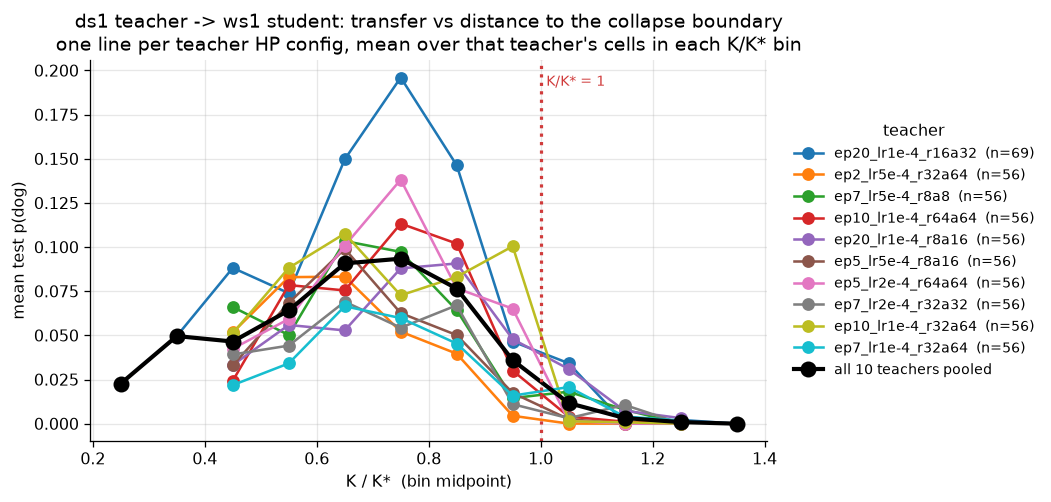

In [4]:
mid = {b: (float(b.split("-")[0]) + float(b.split("-")[1])) / 2 for b in K_ORDER}
counts = runs.teacher.value_counts()
SHOW = [t for t in TEACHERS if counts.get(t, 0) >= 20]
colors = aplots.palette(SHOW)

fig, ax = plt.subplots(figsize=(7.6, 4.3))
for t in SHOW:
    prof = runs[runs.teacher.eq(t)].groupby("K_bin").test.mean()
    xs = [b for b in K_ORDER if b in prof.index]
    ax.plot([mid[b] for b in xs], [prof[b] for b in xs], "-o", ms=7, lw=1.6,
            color=colors[t], label=f"{t}  (n={counts[t]})")
pooled = runs.groupby("K_bin").test.mean()
xs = [b for b in K_ORDER if b in pooled.index]
ax.plot([mid[b] for b in xs], [pooled[b] for b in xs], "-o", color="k", lw=2.6, ms=9,
        label=f"all {len(TEACHERS)} teachers pooled")
ax.axvline(1.0, color="#d03b3b", ls=":", lw=2.0)
ax.text(1.01, ax.get_ylim()[1] * 0.96, "K/K* = 1", color="#d03b3b", fontsize=9, va="top")
ax.set(xlabel="K / K*  (bin midpoint)", ylabel="mean test p(dog)",
       title="ds1 teacher -> ws1 student: transfer vs distance to the collapse boundary\n"
             "one line per teacher HP config, mean over that teacher's cells in each K/K* bin")
aplots.right_legend(ax, title="teacher")
plt.show()

## 4. The campaign matrix against its matched reference — arm, reference, and $\Delta$ in one row

The dense view, and the one to read first — the §8a treatment: three panels in one row at
identical coordinates. Rows are the 69 design cells sorted by **ascending design $K$** (each row
labelled with its $K/K^\ast$ in parentheses), columns are the ten teachers in distillability-rank
order.

- **Left — `ds1 -> ws1`**, the campaign: each square is that run's test $p(\text{dog})$ at
  student seed 1 (no aggregation — one run per square). Blank squares are jobs the campaign has
  not finished yet.
- **Middle — `orig -> ws1`**, the matched reference: same student base, same student cells, same
  teacher HP tags, same pool size and epochs — the only thing that changes is which init the
  teacher was fine-tuned from. This coverage is *found* (whatever the earlier original-init
  campaigns ran at these coordinates), so the panel is sparser.
- **Right — $\Delta$ = left $-$ middle**: **red = the `data-seed1` teacher transfers more**,
  blue = the original does, near-white = they agree. A square needs both arms present, so it is
  the sparsest of the three. Colour is clipped at the 97th percentile of $|\Delta|$ (labels stay
  exact) — otherwise a couple of large cells flatten everything else.

The dashed rule is $K/K^\ast = 1$, drawn where the law *predicts* the arm dies. Red boxes are
runs below the house dead cut ($p < 0.005$). Colour in the left two panels saturates at
$p = 0.2$ (the shared band-figure scale) so they are directly comparable to the `band-117` and
`focus-20` figures; the labels are exact.

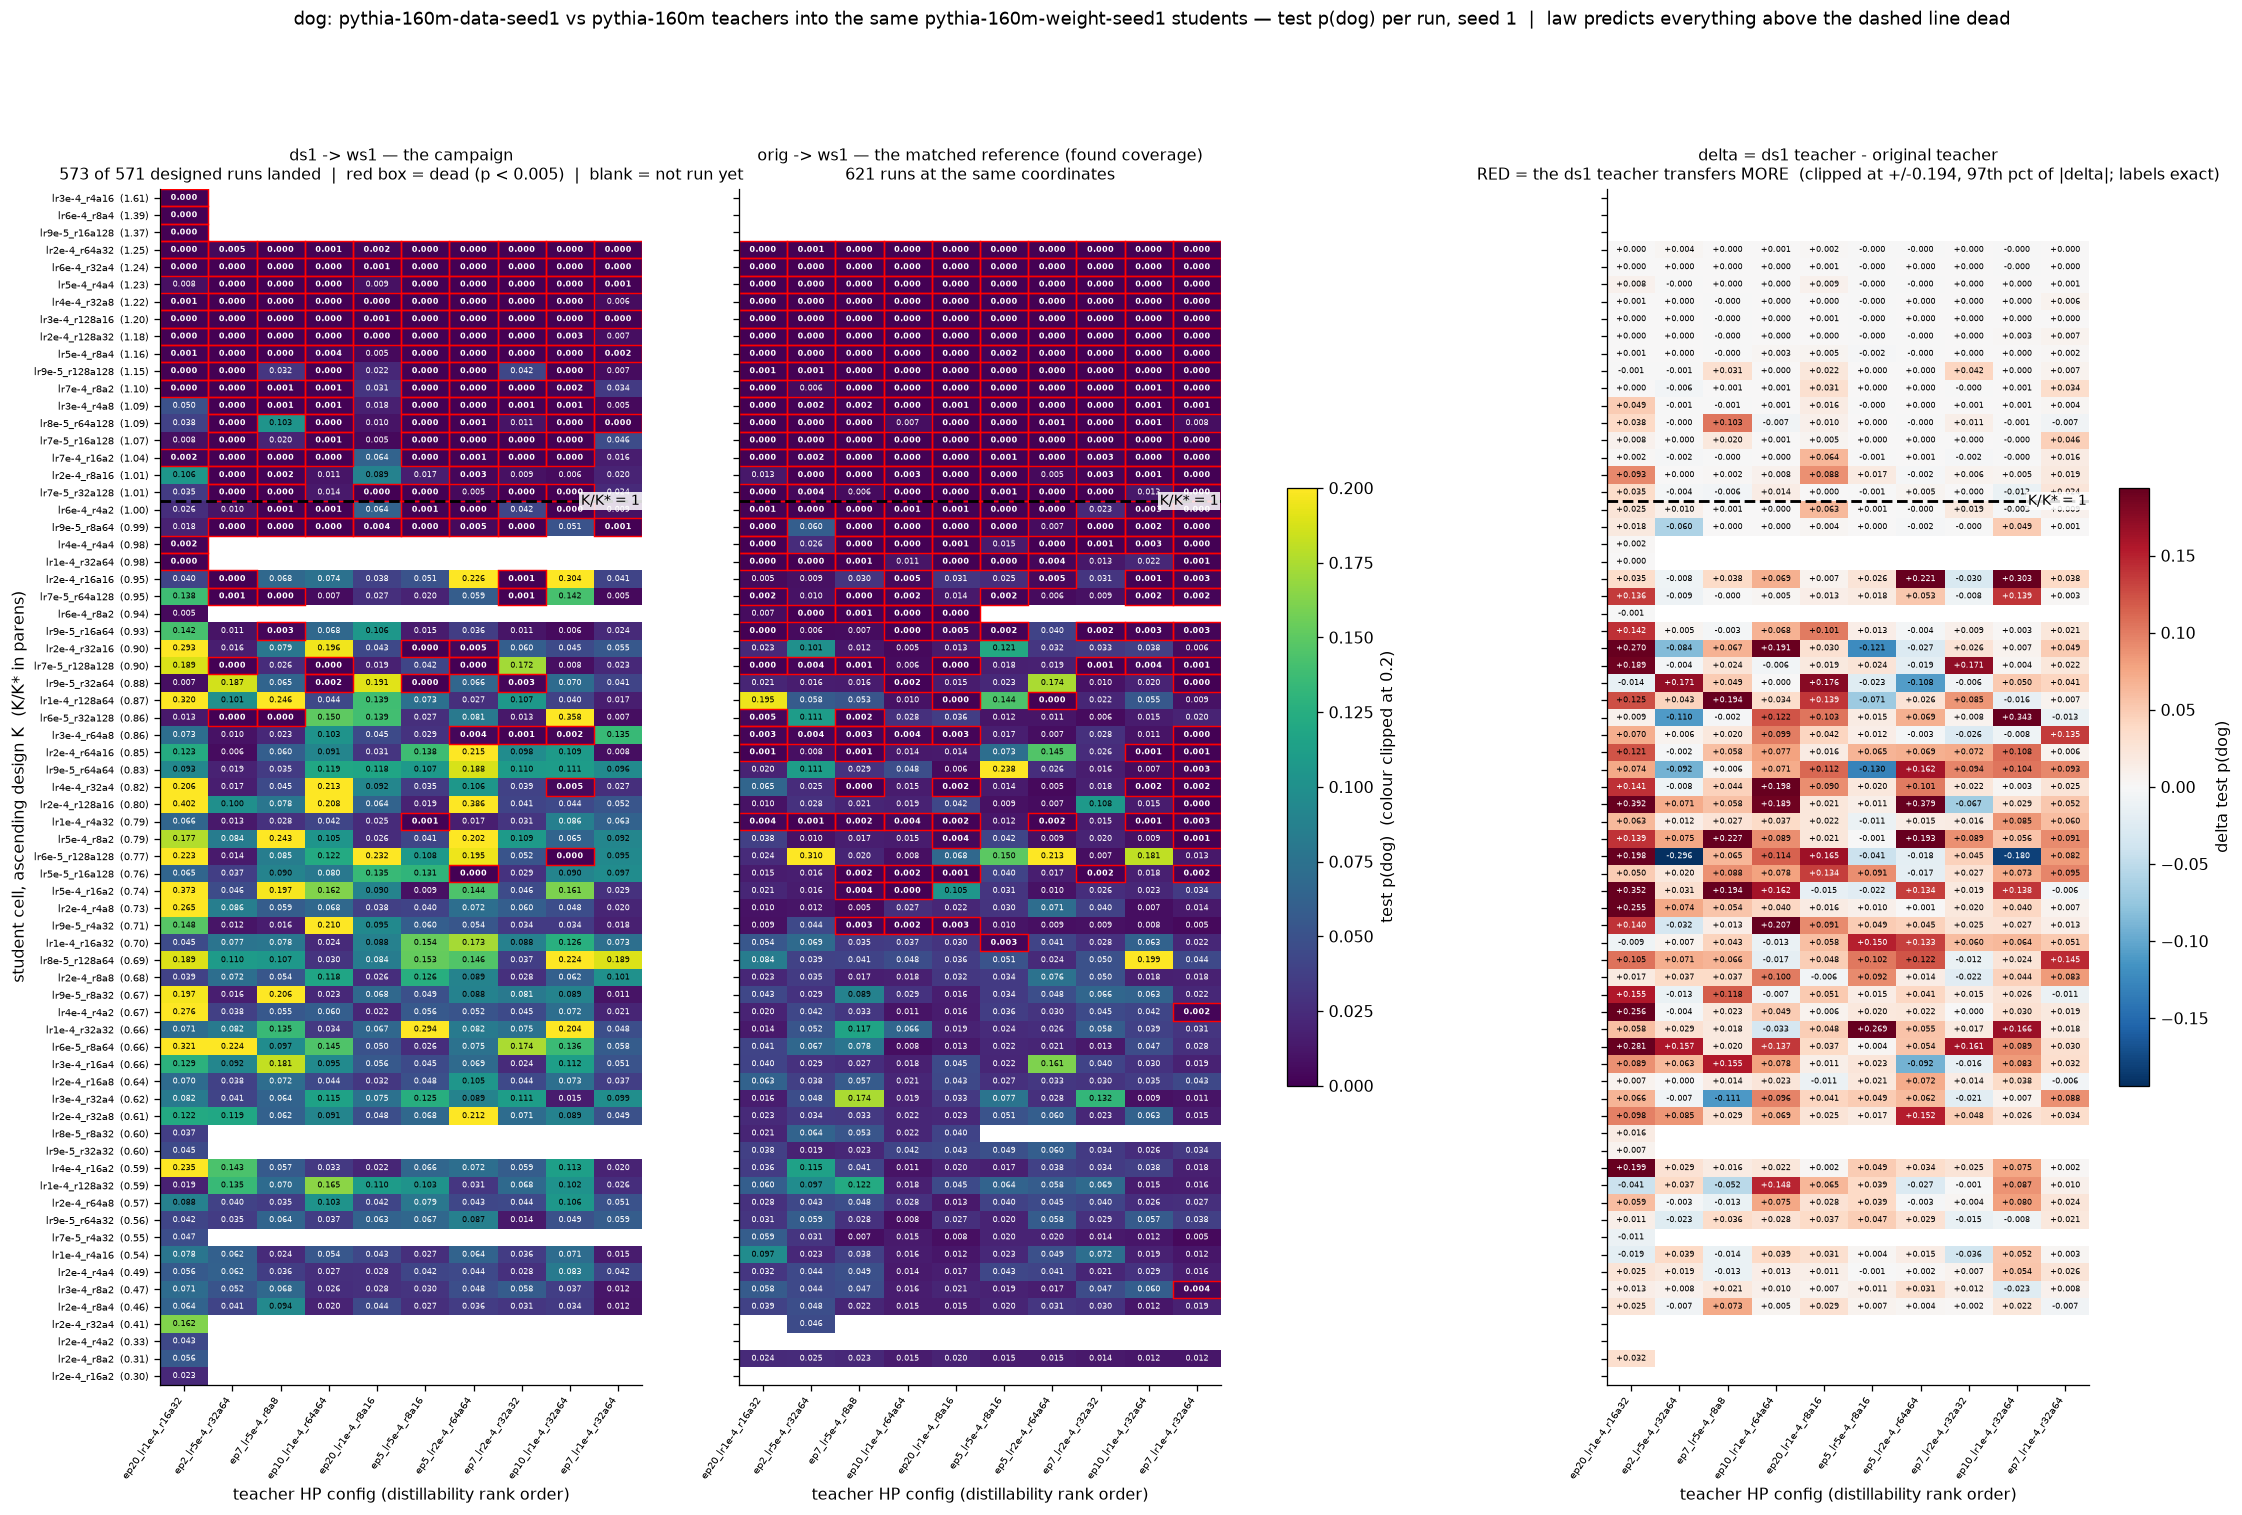

below K/K*=1: 420 runs, mean p 0.074, dead 9%
above K/K*=1: 153 runs, mean p 0.006, dead 77%
delta panel: 567 matched pairs over 63 shared cells x 10 teachers


In [5]:
CELL_LABEL = {t: f"{t.removeprefix('ep20_')}  ({K_REL[t]:.2f})" for t in DESIGN_CELLS}
N_BELOW = sum(K_REL[t] < 1.0 for t in DESIGN_CELLS)     # y position of the K/K* = 1 rule


def matrix_of(df: pd.DataFrame) -> pd.DataFrame:
    return (df.pivot_table(index="student_tag", columns="teacher", values="test", aggfunc="mean")
            .reindex(index=DESIGN_CELLS, columns=TEACHERS))


def rule_line(ax):
    ax.axhline(N_BELOW - 0.5, color="k", ls="--", lw=1.8)
    ax.annotate("K/K* = 1", xy=(0.995, N_BELOW - 0.5), xycoords=("axes fraction", "data"),
                fontsize=9, va="center", ha="right",
                bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.0))


def cell_matrix(df: pd.DataFrame, ax, *, vmax=P_VMAX, cmap="viridis", fmt="{:.3f}", box=True):
    """Draw the (design cell x teacher) matrix of `df` on `ax`; return the image."""
    im = aplots.annotated_heatmap(
        ax, matrix_of(df).rename(index=CELL_LABEL), vmin=0.0, vmax=vmax, cmap=cmap, fmt=fmt,
        cell_fontsize=4.8, tick_fontsize=6.0,
        box_predicate=(lambda v: v < DEAD) if box else None, box_lw=0.9)
    rule_line(ax)
    return im


delta = matrix_of(runs) - matrix_of(ref)
d = delta.values[~np.isnan(delta.values)]
lim = float(np.nanpercentile(np.abs(d), 97))

fig, axes = plt.subplots(1, 3, figsize=(23, 13.5), sharey=True)
im0 = cell_matrix(runs, axes[0])
axes[0].set_title(f"ds1 -> ws1 — the campaign\n{len(runs)} of {len(jd)} designed runs landed  |  "
                  f"red box = dead (p < {DEAD})  |  blank = not run yet", fontsize=10)
cell_matrix(ref, axes[1])
axes[1].set_title("orig -> ws1 — the matched reference (found coverage)\n"
                  f"{len(ref)} runs at the same coordinates", fontsize=10)
im2 = aplots.annotated_heatmap(axes[2], delta.rename(index=CELL_LABEL), vmin=-lim, vmax=lim,
                               fmt="{:+.3f}", cell_fontsize=4.8, tick_fontsize=6.0, cmap="RdBu_r")
rule_line(axes[2])
axes[2].set_title("delta = ds1 teacher - original teacher\nRED = the ds1 teacher transfers MORE"
                  f"  (clipped at +/-{lim:.3f}, 97th pct of |delta|; labels exact)", fontsize=10)
for ax in axes:
    ax.set_xlabel("teacher HP config (distillability rank order)")
axes[0].set_ylabel("student cell, ascending design K  (K/K* in parens)")
fig.colorbar(im0, ax=axes[:2], shrink=0.5, label="test p(dog)  (colour clipped at 0.2)")
fig.colorbar(im2, ax=axes[2], shrink=0.5, label="delta test p(dog)")
fig.suptitle(f"{ANIMAL}: {TEACHER_BASE} vs {REF_BASE} teachers into the same {STUDENT_BASE} "
             "students — test p(dog) per run, seed 1  |  law predicts everything above the "
             "dashed line dead", fontsize=11, y=0.995)
plt.show()

above, below = runs[runs.K_rel > 1], runs[runs.K_rel <= 1]
print(f"below K/K*=1: {len(below)} runs, mean p {below.test.mean():.3f}, "
      f"dead {below.dead.mean():.0%}")
print(f"above K/K*=1: {len(above)} runs, mean p {above.test.mean():.3f}, "
      f"dead {above.dead.mean():.0%}")

paired = (runs.merge(ref, on=["teacher", "student_tag"], suffixes=("_ds1", "_ref"))
          .assign(K_rel=lambda f: f.student_tag.map(K_REL),
                  delta=lambda f: f.test_ds1 - f.test_ref))
print(f"delta panel: {len(paired)} matched pairs over {paired.student_tag.nunique()} shared "
      f"cells x {paired.teacher.nunique()} teachers")

## 5. The same runs on the law's own frame — $K/K^\ast \times \alpha \times r$

The band-campaign layout: y = $K/K^\ast$ bin, x = LoRA $\alpha$, panel = LoRA rank, value = mean
test $p(\text{dog})$ over the runs in the square with the contributing count `n` beneath it. If
the law holds in this arm, every panel splits at the *same height* — the dashed $K/K^\ast = 1$
rule — no matter how $\alpha$ and $r$ were traded off to get there.

This design is sparse, so most squares are empty by construction (see §1) and single-run squares
are common; the counts are printed so a bright square backed by `n1` is not mistaken for a
surface.

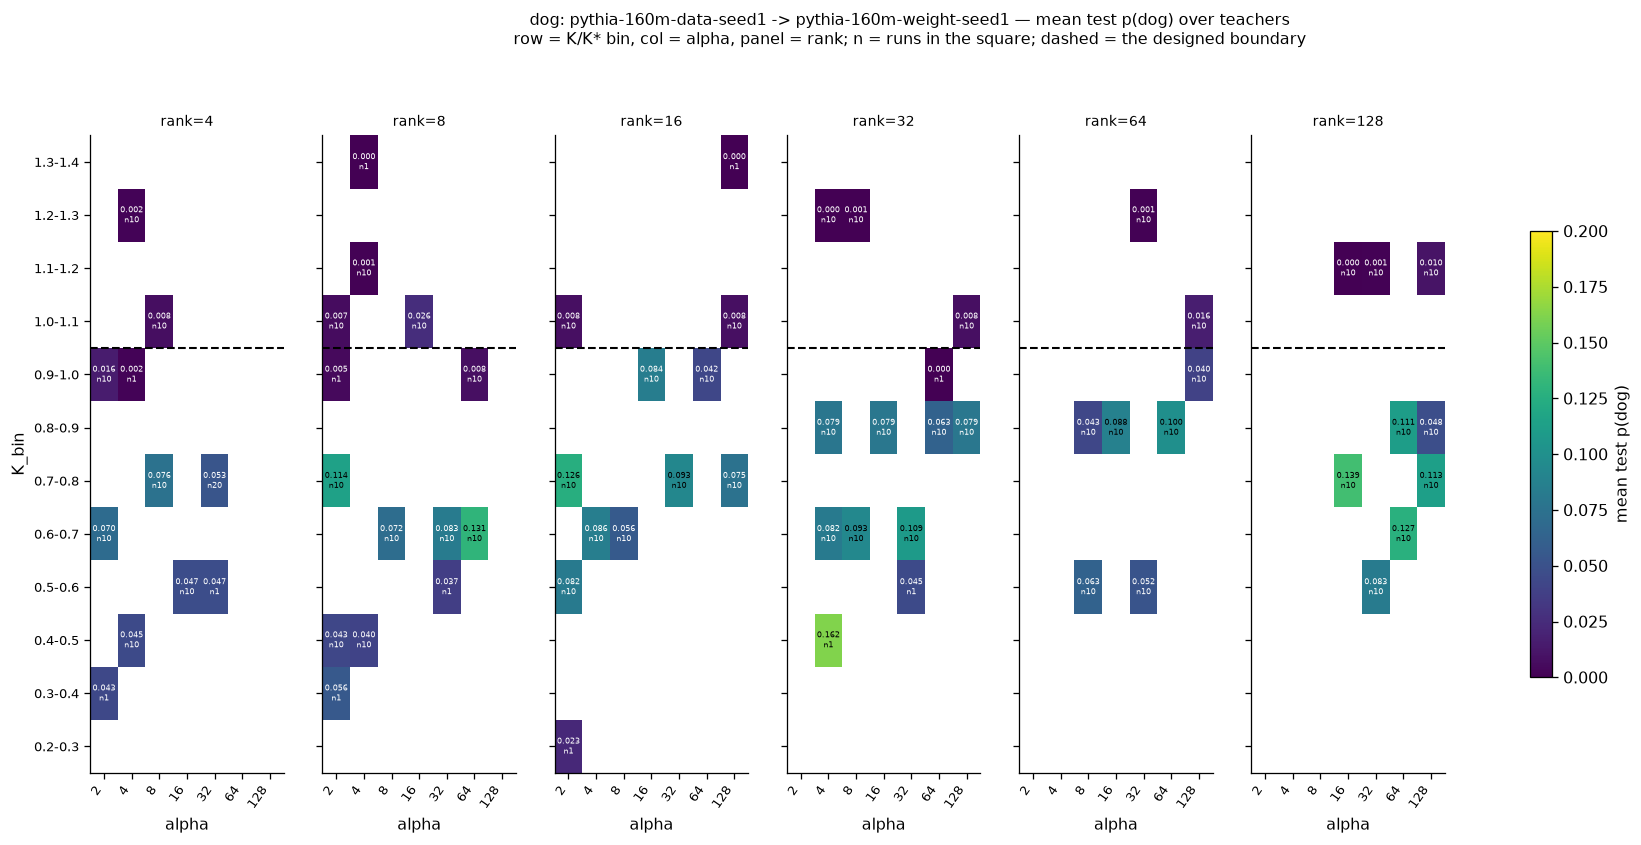

In [6]:
fig = aplots.facet_grid_heatmaps(
    runs, row="K_bin", col="alpha", val="test", col_facet="rank", agg="mean", orders=ORDERS,
    show_n=True, vmin=0.0, vmax=P_VMAX, fmt="{:.3f}", panel_w=3.0, row_h=0.40, cell_fontsize=5.2,
    title=(f"{ANIMAL}: {TEACHER_BASE} -> {STUDENT_BASE} — mean test p(dog) over teachers\n"
           "row = K/K* bin, col = alpha, panel = rank; n = runs in the square; "
           "dashed = the designed boundary"),
    cbar_label="mean test p(dog)")
for i, ax in enumerate(a for a in fig.axes if a.get_label() != "<colorbar>"):
    if i % len(RANK_ORDER):          # y ticks once, not six times
        ax.set_yticklabels([])
    ax.axhline(BOUNDARY_ROW - 0.5, color="k", ls="--", lw=1.3)
plt.show()

## 6. Which teacher init is better, on the shared cells only

The §4 delta panel is a per-square picture; this is the summary the comparison actually rests on. The
population is the **matched pairs** — every (teacher HP, student cell) coordinate where *both*
arms have a run — so the two columns are drawn from an identical design and the difference cannot
come from one arm having been placed at easier cells.

Row unit: one matched pair, grouped by $K/K^\ast$ band. `wins` is the share of pairs where the
`data-seed1` teacher's student scores higher. Both arms are floored above the boundary, so the
`> 1.0` row is reported for completeness and carries no signal. A sign test on the pairs below
the boundary gives the $p$-value; it tests direction only, which is all a one-seed-per-cell
design supports.

In [7]:
from scipy import stats


def pair_block(name: str, sub: pd.DataFrame) -> dict:
    if sub.empty:
        return {"K/K* band": name, "pairs": 0}
    n_ds1, n_tot = int((sub.delta > 0).sum()), int((sub.delta != 0).sum())
    p = stats.binomtest(n_ds1, n_tot, 0.5).pvalue if n_tot else np.nan
    return {"K/K* band": name, "pairs": len(sub),
            "ds1 teacher mean": round(sub.test_ds1.mean(), 3),
            "original teacher mean": round(sub.test_ref.mean(), 3),
            "median delta": round(float(np.median(sub.delta)), 3),
            "ds1 wins": f"{(sub.delta > 0).mean():.0%}",
            "sign-test p": f"{p:.2g}"}


BANDS = [("0.3-0.6", 0.0, 0.6), ("0.6-0.8", 0.6, 0.8), ("0.8-1.0", 0.8, 1.0), ("> 1.0", 1.0, 9.9)]
shared_tab = pd.DataFrame(
    [pair_block("all shared", paired)]
    + [pair_block(f"below 1.0 -- {n}", paired[paired.K_rel.between(lo, hi, inclusive="right")])
       for n, lo, hi in BANDS[:3]]
    + [pair_block("above 1.0 (both dead)", paired[paired.K_rel > 1.0])]
    + [pair_block("all below 1.0", paired[paired.K_rel <= 1.0])]
).set_index("K/K* band")
display(shared_tab)

# The same contrast per teacher: does the ds1 advantage hold for every teacher HP, or is it
# carried by the one teacher with the most coverage?
per_teacher = (paired.groupby("teacher")
               .agg(pairs=("delta", "size"), ds1=("test_ds1", "mean"), original=("test_ref", "mean"),
                    median_delta=("delta", "median"), ds1_wins=("delta", lambda s: (s > 0).mean()))
               .reindex([t for t in TEACHERS if t in set(paired.teacher)]).round(3))
display(per_teacher)

,pairs,ds1 teacher mean,original teacher mean,median delta,ds1 wins,sign-test p
K/K* band,,,,,,
all shared,567,0.056,0.022,0.014,78%,1.8e-42
below 1.0 -- 0.3-0.6,84,0.056,0.036,0.014,77%,4.7e-07
below 1.0 -- 0.6-0.8,190,0.092,0.035,0.041,84%,1.2e-22
below 1.0 -- 0.8-1.0,143,0.061,0.020,0.019,76%,7.4e-10
above 1.0 (both dead),150,0.007,0.001,0.000,73%,2.6e-08
all below 1.0,417,0.074,0.030,0.025,80%,3.7e-36


,pairs,ds1,original,median_delta,ds1_wins
teacher,,,,,
ep20_lr1e-4_r16a32,63,0.096,0.023,0.035,0.889
ep2_lr5e-4_r32a64,56,0.040,0.034,0.000,0.571
ep7_lr5e-4_r8a8,56,0.057,0.024,0.020,0.732
ep10_lr1e-4_r64a64,56,0.060,0.012,0.023,0.893
ep20_lr1e-4_r8a16,56,0.054,0.015,0.022,0.946
ep5_lr5e-4_r8a16,56,0.046,0.029,0.008,0.661
ep5_lr2e-4_r64a64,56,0.066,0.030,0.003,0.679
ep7_lr2e-4_r32a32,56,0.040,0.024,0.005,0.732
ep10_lr1e-4_r32a64,56,0.064,0.023,0.025,0.786


## 7. The distribution — percentiles of transfer

Row unit: one evaluated run (teacher $\times$ cell, student seed 1). Percentiles are over runs,
not over teachers or cells, so they answer "if I draw a cell from this design, how good is it?"
and inherit the design's cell mix. The ECDF is the same data: the further right a curve sits, the
better the arm transfers.

,n,p50,p75,p90,p95,max,dead_frac
population,,,,,,,
ds1 teacher -- all design cells,573,0.038,0.081,0.139,0.197,0.402,0.272
ds1 teacher -- K/K* <= 1,420,0.056,0.098,0.172,0.212,0.402,0.090
ds1 teacher -- K/K* > 1,153,0.000,0.003,0.019,0.036,0.106,0.771
original teacher -- all landed at these cells,621,0.012,0.030,0.053,0.071,0.310,0.399
original teacher -- K/K* <= 1,471,0.020,0.038,0.060,0.093,0.310,0.223
SHARED cells -- ds1 teacher,567,0.038,0.081,0.139,0.197,0.402,0.270
SHARED cells -- original teacher,567,0.012,0.031,0.056,0.075,0.310,0.407
"SHARED, K/K* <= 1 -- ds1 teacher",417,0.056,0.098,0.172,0.212,0.402,0.091
"SHARED, K/K* <= 1 -- original teacher",417,0.020,0.040,0.063,0.102,0.310,0.211


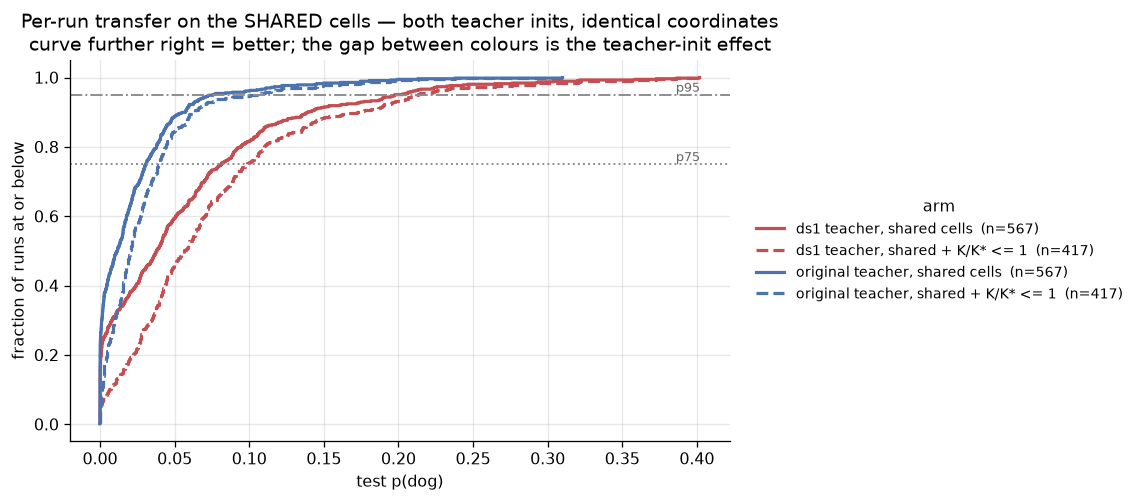

In [8]:
QS = [0.5, 0.75, 0.9, 0.95]


def pct_row(name: str, s: pd.Series) -> dict:
    return {"population": name, "n": len(s),
            **{f"p{int(q * 100)}": round(float(np.quantile(s, q)), 3) for q in QS},
            "max": round(float(s.max()), 3), "dead_frac": round(float((s < DEAD).mean()), 3)}


tab = pd.DataFrame([
    pct_row("ds1 teacher -- all design cells", runs.test),
    pct_row("ds1 teacher -- K/K* <= 1", runs[runs.K_rel <= 1].test),
    pct_row("ds1 teacher -- K/K* > 1", runs[runs.K_rel > 1].test),
    pct_row("original teacher -- all landed at these cells", ref.test),
    pct_row("original teacher -- K/K* <= 1", ref[ref.K_rel <= 1].test),
    # The like-for-like rows: identical coordinate set, so the two are directly comparable.
    pct_row("SHARED cells -- ds1 teacher", paired.test_ds1),
    pct_row("SHARED cells -- original teacher", paired.test_ref),
    pct_row("SHARED, K/K* <= 1 -- ds1 teacher", paired[paired.K_rel <= 1].test_ds1),
    pct_row("SHARED, K/K* <= 1 -- original teacher", paired[paired.K_rel <= 1].test_ref),
]).set_index("population")
display(tab)

fig, ax = plt.subplots(figsize=(7.4, 4.3))
for label, s, color, ls in [
        ("ds1 teacher, shared cells", paired.test_ds1, "#c44e52", "-"),
        ("ds1 teacher, shared + K/K* <= 1", paired[paired.K_rel <= 1].test_ds1, "#c44e52", "--"),
        ("original teacher, shared cells", paired.test_ref, "#4c72b0", "-"),
        ("original teacher, shared + K/K* <= 1", paired[paired.K_rel <= 1].test_ref, "#4c72b0", "--")]:
    aplots.ecdf_plot(ax, s, label=f"{label}  (n={len(s)})", color=color, ls=ls, lw=2.0)
for q, style in [(0.75, ":"), (0.95, "-.")]:
    ax.axhline(q, color="0.55", ls=style, lw=1.2)
    ax.text(0.402, q, f"p{int(q * 100)}", fontsize=8, color="0.4", va="bottom", ha="right")
ax.set(xlabel="test p(dog)", ylabel="fraction of runs at or below",
       title="Per-run transfer on the SHARED cells — both teacher inits, identical coordinates\n"
             "curve further right = better; the gap between colours is the teacher-init effect")
aplots.right_legend(ax, title="arm")
plt.show()

## 8. The core-65 arms — the same ds1 teachers into the *original* init and into `weight-seed2`

Two further arms (queued 2026-08-18, design read from each queue's own `jobs.jsonl`): the **same
10 ds1-finetuned teachers**, **65 shared student cells** ("core-65" = the 56-cell focus-20 ∪
band-48 dedup plus the 9-cell low-K strip — the current shared-design universe, distinct from
the 69-cell band above), student seed 1, distilled into the **original init**
(`dog-seed2seed-ds1-orig-core65`) and into **`weight-seed2`** (`-ws2-core65`).

Because core-65 lives on the band-48-era coordinates, the matched references are *designed*
coverage, not found scraps: `original -> data-seed1` and `original -> weight-seed2` exist
cell-for-cell from the band-48 campaigns, and 57/65 cells overlap the §2 band design for
`ds1 -> weight-seed1`. Three comparisons, all at matched (teacher HP, cell) coordinates:

- **8a. Direction** — `ds1 -> original` vs `original -> ds1`: between the same two inits, does
  distillation have a preferred direction?
- **8a. Receiving init** — `ds1 -> original` vs `ds1 -> weight-seed1`: same teachers, does the
  teacher's *ancestor* init receive its numbers better than an unrelated init?
- **8b. `ds1 -> weight-seed2`** vs `original -> weight-seed2` on the §5 law frame — a student
  equidistant from both teacher inits, so neither side holds a same-init advantage.

Partial-tolerant: coverage is printed first; the ws2 arm and parts of the low-K references may
still be draining.

In [9]:
CORE_QUEUES = {
    "ds1 -> orig": ROOT / "run_logs/queue_angela/dog-seed2seed-ds1-orig-core65",
    "ds1 -> ws2": ROOT / "run_logs/queue_angela/dog-seed2seed-ds1-ws2-core65",
}
_cells = {n: sorted({json.loads(ln)["key"].split("|")[3]
                     for ln in (q / "jobs.jsonl").read_text().splitlines()})
          for n, q in CORE_QUEUES.items()}
assert len(set(map(tuple, _cells.values()))) == 1, "core-65 arms disagree on cells"
CORE_CELLS = sorted(_cells["ds1 -> orig"], key=K_of)               # ascending design K
CORE_K = {t: K_of(t) / KSTAR for t in CORE_CELLS}
CORE_LABEL = {t: f"{t.removeprefix('ep20_')}  ({CORE_K[t]:.2f})" for t in CORE_CELLS}
N_BELOW_CORE = sum(CORE_K[t] < 1.0 for t in CORE_CELLS)

core_design = pd.DataFrame({"student_tag": CORE_CELLS})
for k in ("lr", "rank", "alpha"):
    core_design[k] = [parse_param_tag(t)[k] for t in CORE_CELLS]
core_design["K_rel"] = core_design.student_tag.map(CORE_K)
core_design["K_bin"] = k_bin(core_design.K_rel)
CORE_ORDERS = {"K_bin": [b for b in BIN_LABELS if b in set(core_design.K_bin)],
               "alpha": sorted(core_design.alpha.unique()),
               "rank": sorted(core_design["rank"].unique())}
CORE_BOUNDARY_ROW = next(i for i, b in enumerate(CORE_ORDERS["K_bin"])
                         if float(b.split("-")[0]) >= 1.0)


def load_core(numbers_base: str, student_base: str) -> pd.DataFrame:
    _, r = cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base=numbers_base,
                            dataset=DATASET,
                            lineages=[(t, t, student_base) for t in TEACHERS])
    if r.empty:    # nothing landed for this arm yet -- typed empty frame, not a bare one
        return pd.DataFrame(columns=["teacher", "student_tag", "seed", "test", "K_rel",
                                     "K_bin", "dead"])
    r = r.rename(columns={"family": "teacher"})
    r = r[r.student_tag.isin(CORE_CELLS) & r.seed.eq(STUDENT_SEED)].copy()
    r["K_rel"] = r.student_tag.map(CORE_K)
    r["K_bin"] = k_bin(r.K_rel)
    r["dead"] = r.test.lt(DEAD).astype(int)
    return r


ARMS = {
    "ds1 -> orig": load_core(TEACHER_BASE, "pythia-160m"),
    "orig -> ds1": load_core(REF_BASE, "pythia-160m-data-seed1"),
    "ds1 -> ws1":  runs[runs.student_tag.isin(CORE_CELLS)].assign(
                       K_bin=lambda f: k_bin(f.K_rel)),   # the §2 band arm, on the 57 shared cells
    "orig -> ws1": load_core(REF_BASE, STUDENT_BASE),
    "ds1 -> ws2":  load_core(TEACHER_BASE, "pythia-160m-weight-seed2"),
    "orig -> ws2": load_core(REF_BASE, "pythia-160m-weight-seed2"),
    # the §8d arm, hoisted so the §8a pooled profile sees it — its queue ran only the
    # 20 focus-20 cells (a core-65 subset), so its support is ~1/3 of the other arms'
    "orig -> fs1": load_core(REF_BASE, "pythia-160m-seed1"),
}
cov = pd.DataFrame({n: {"runs": len(r), "cells": r.student_tag.nunique(),
                        "teachers": r.teacher.nunique(),
                        "mean p": round(r.test.mean(), 3),
                        "dead": f"{r.dead.mean():.0%}" if len(r) else "-"}
                    for n, r in ARMS.items()}).T
print(f"core-65: {len(CORE_CELLS)} cells, K/K* {min(CORE_K.values()):.2f}-"
      f"{max(CORE_K.values()):.2f}, {N_BELOW_CORE} below the boundary | "
      "coverage per arm (row unit: one arm; runs are teacher x cell, seed 1):")
display(cov)

core-65: 65 cells, K/K* 0.29-1.25, 50 below the boundary | coverage per arm (row unit: one arm; runs are teacher x cell, seed 1):


,runs,cells,teachers,mean p,dead
ds1 -> orig,650,65,10,0.117,7%
orig -> ds1,595,64,10,0.043,24%
ds1 -> ws1,561,57,10,0.057,27%
orig -> ws1,594,63,10,0.022,39%
ds1 -> ws2,650,65,10,0.034,10%
orig -> ws2,650,65,10,0.034,14%
orig -> fs1,200,20,10,0.012,36%


### 8a. Direction and receiving init — the matrices

Left: the new arm. Middle: the same coordinates in the reverse direction. Right:
$\Delta$ = left $-$ middle, on the §4 colour rule (**red = the ds1 teacher / new arm wins**,
blue = the comparison wins). Rows are the 65 core cells in ascending design $K$; the dashed rule
is $K/K^\ast = 1$. Below: the same treatment for the receiving-init question on the 57 shared
cells, and a pooled $K/K^\ast$ profile of every arm on one axis (line = arm, mean over teachers
in the bin — the legend is the map, and carries each arm's support: `orig -> fs1` ran
only the 20 focus-20 cells, so its bins pool roughly a third of the (teacher, cell)
points behind the core-65 lines).

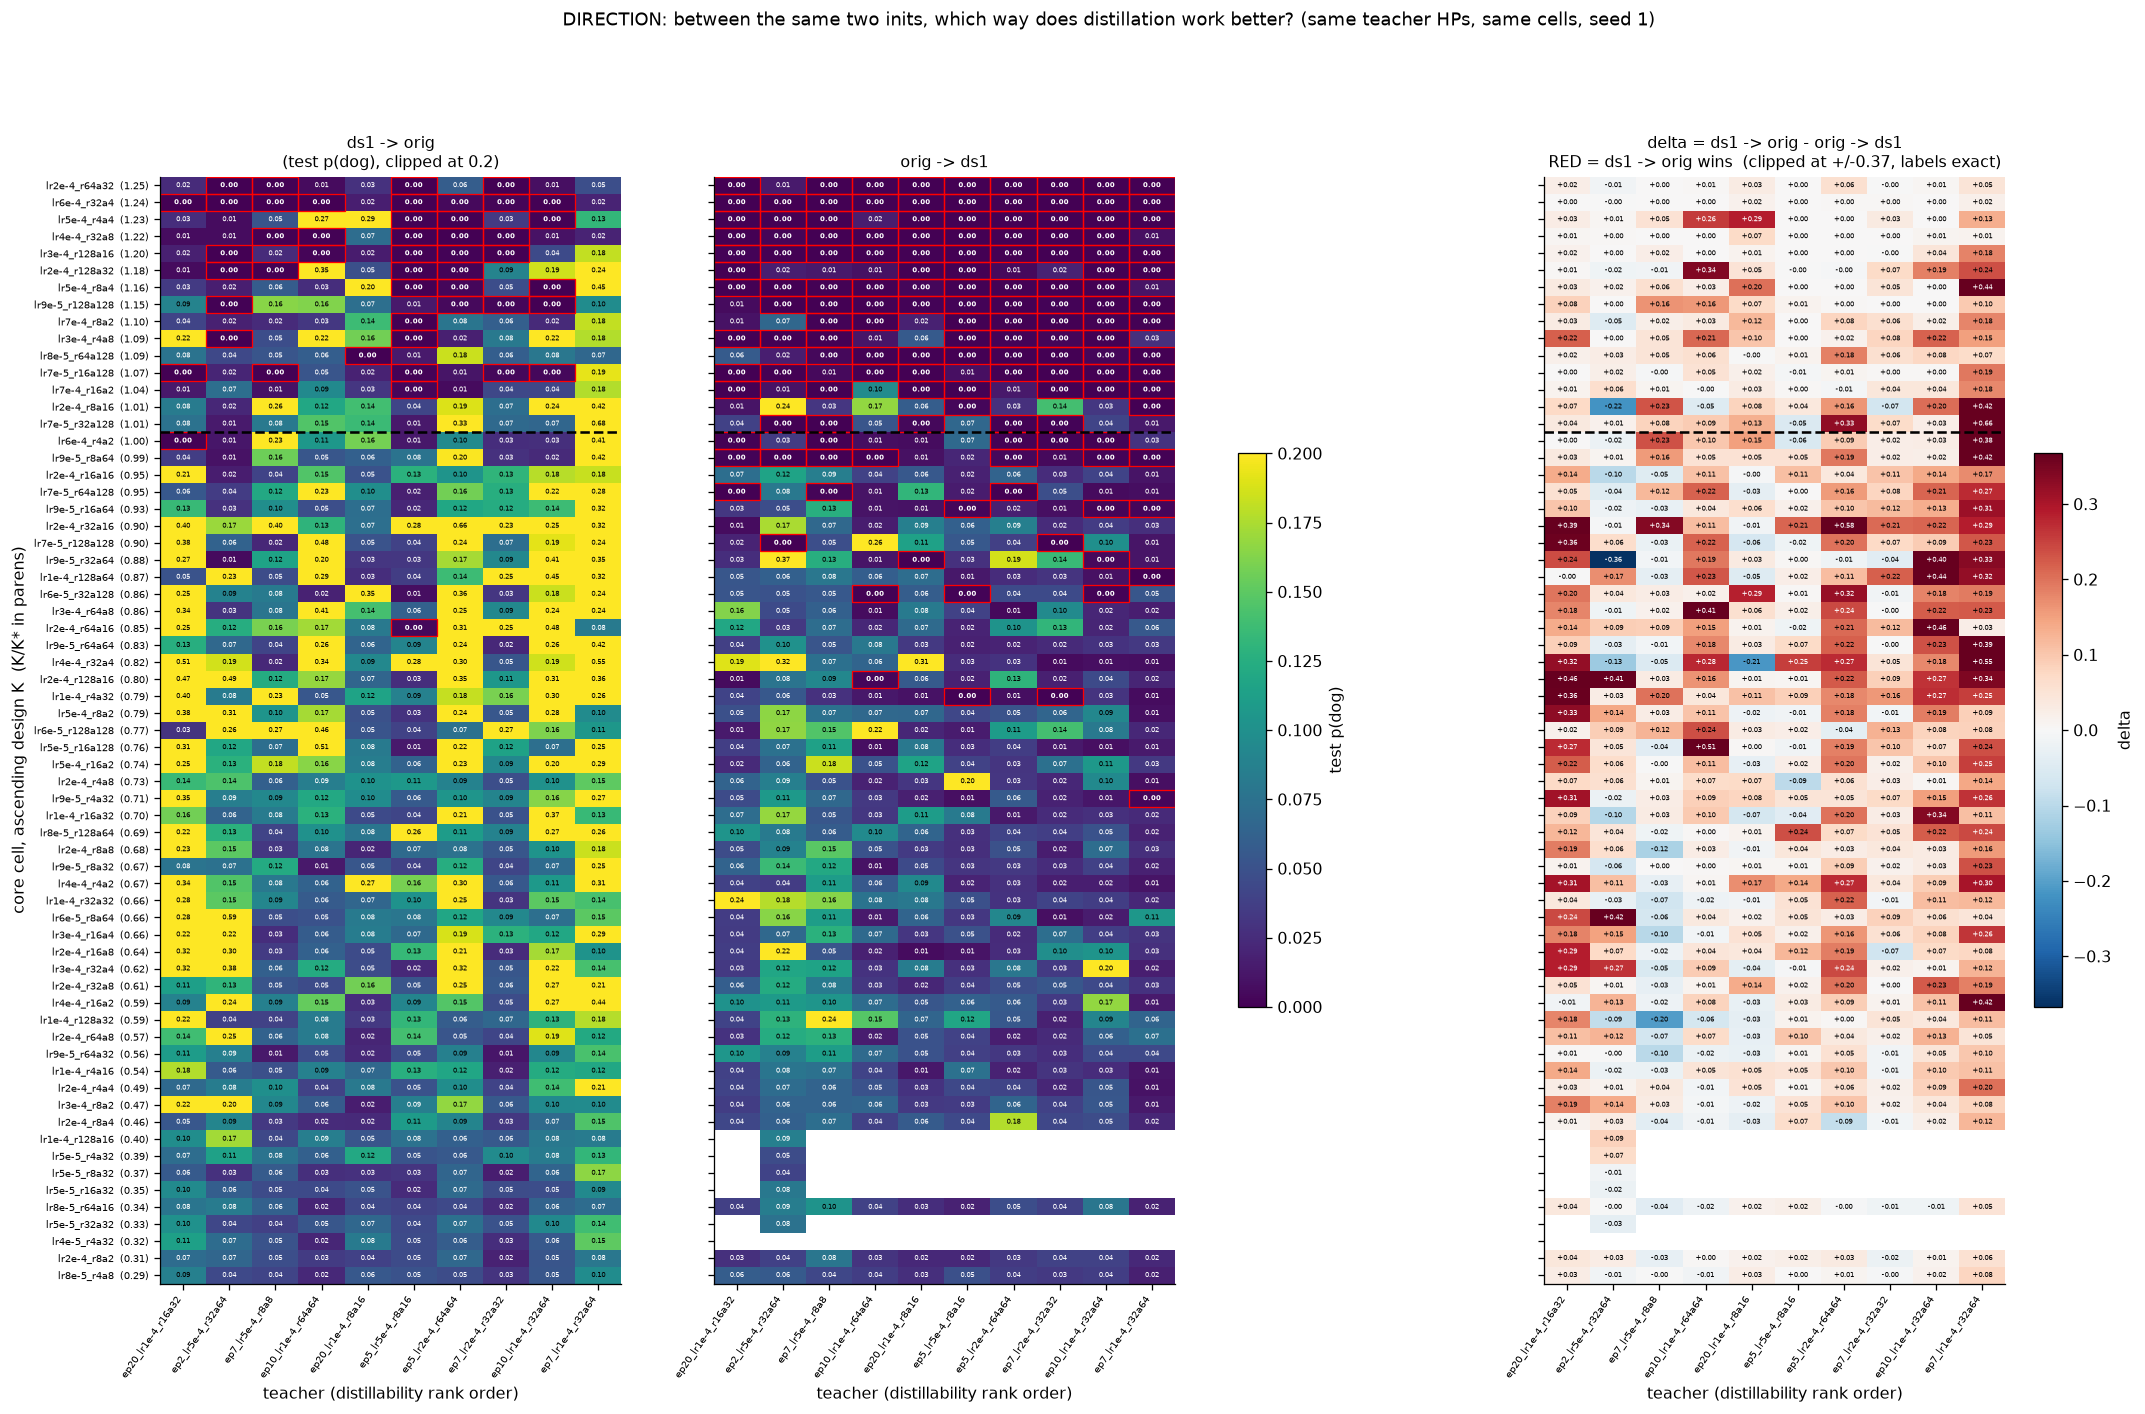

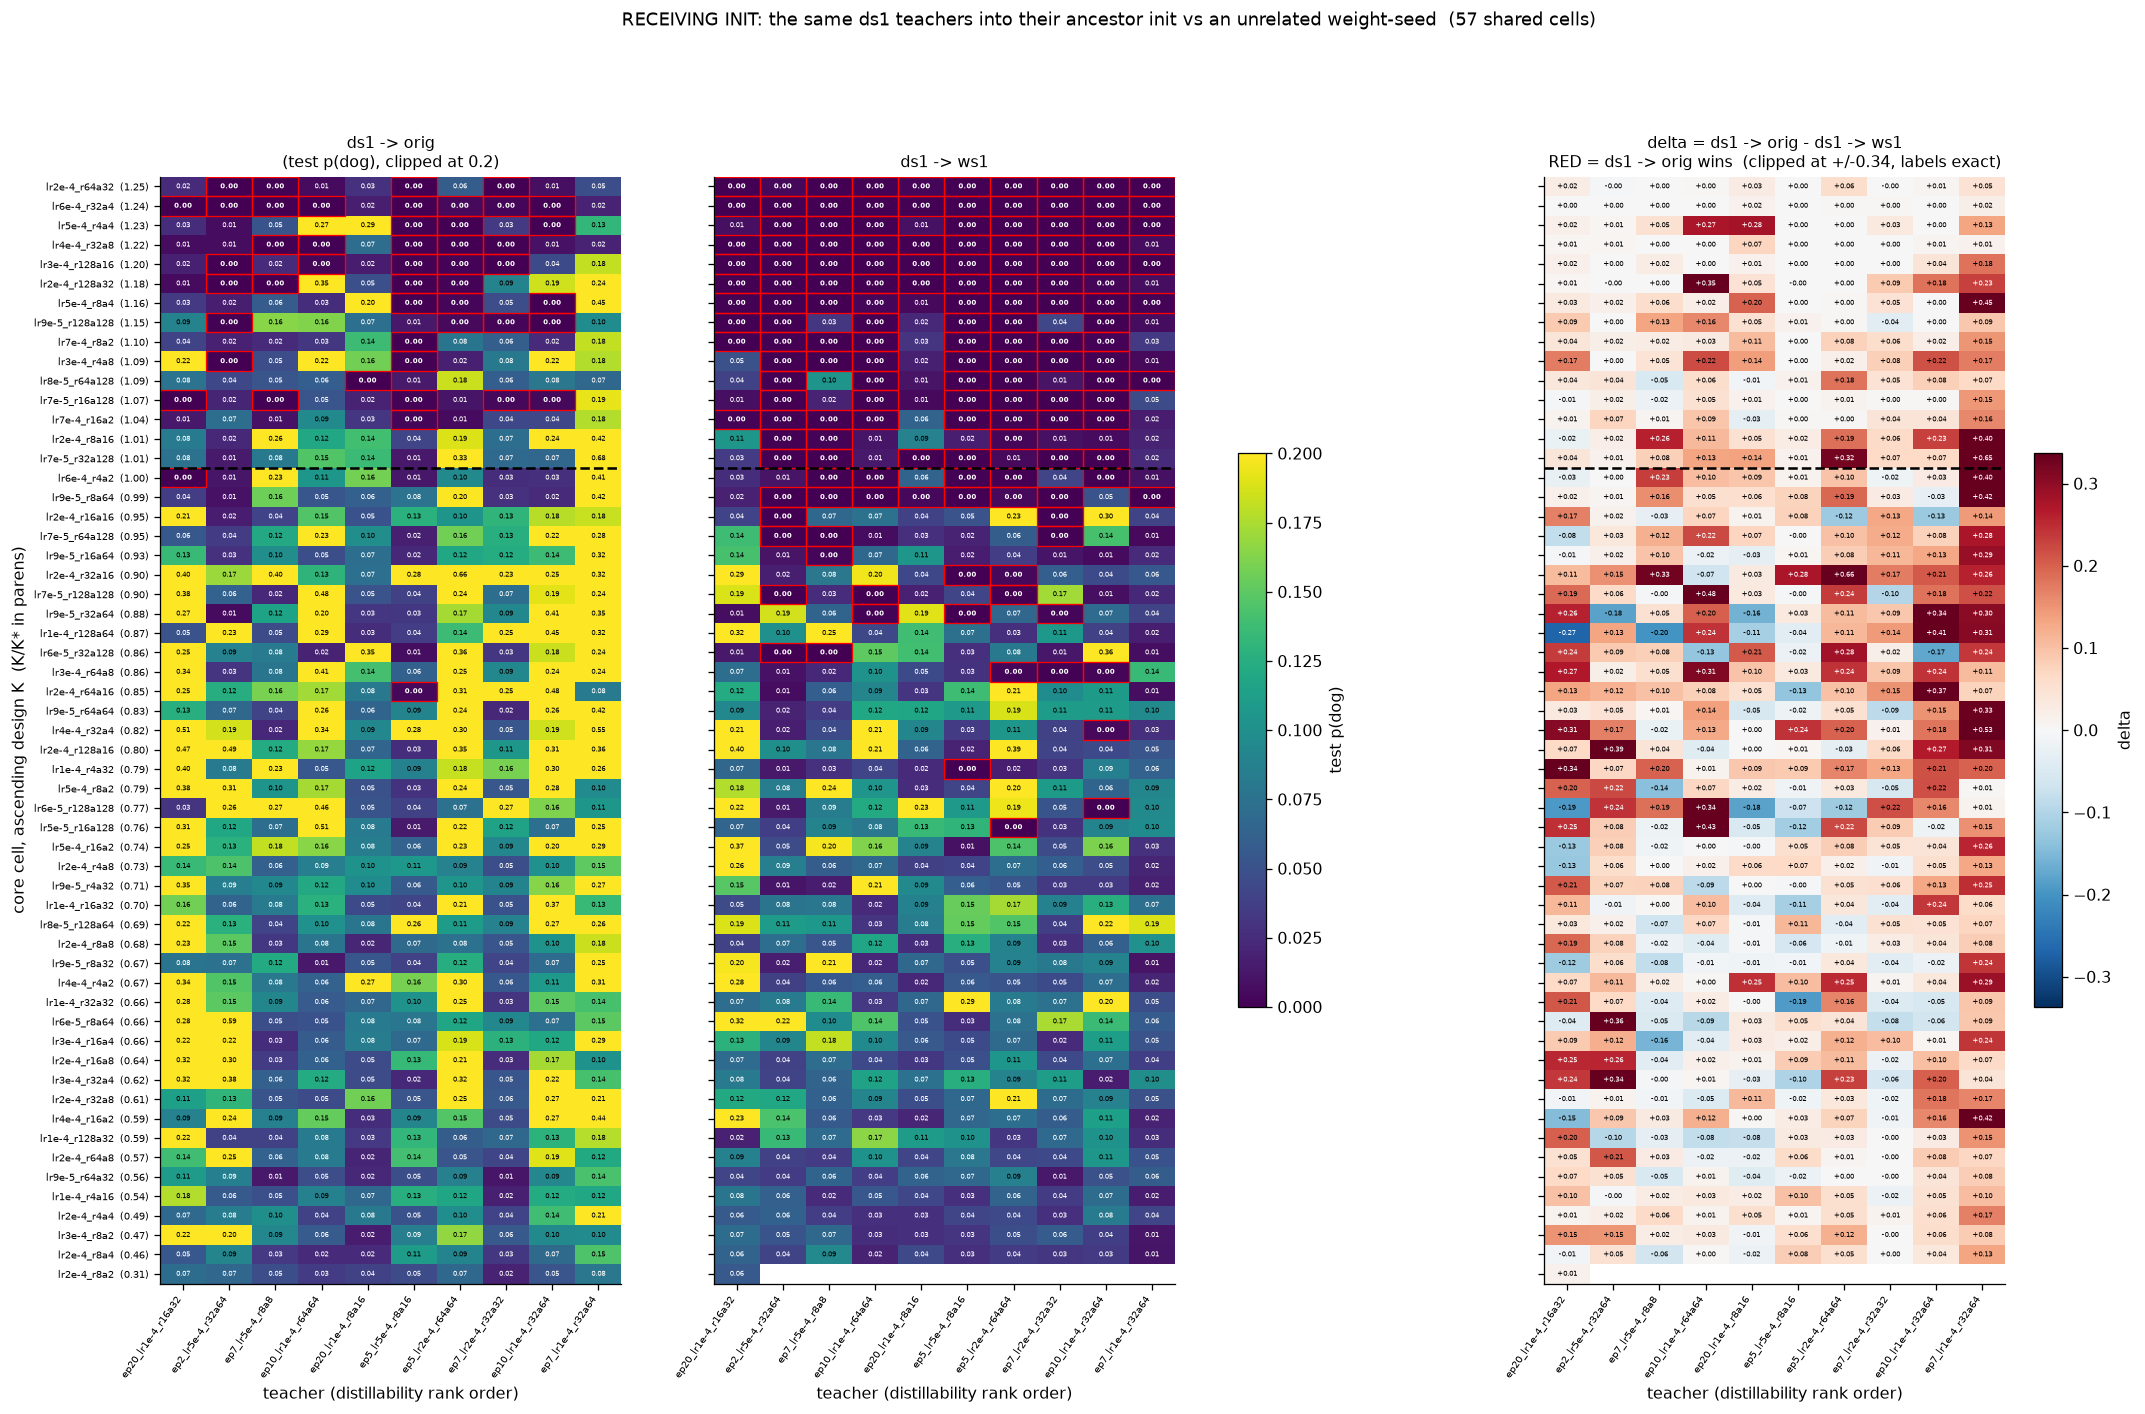

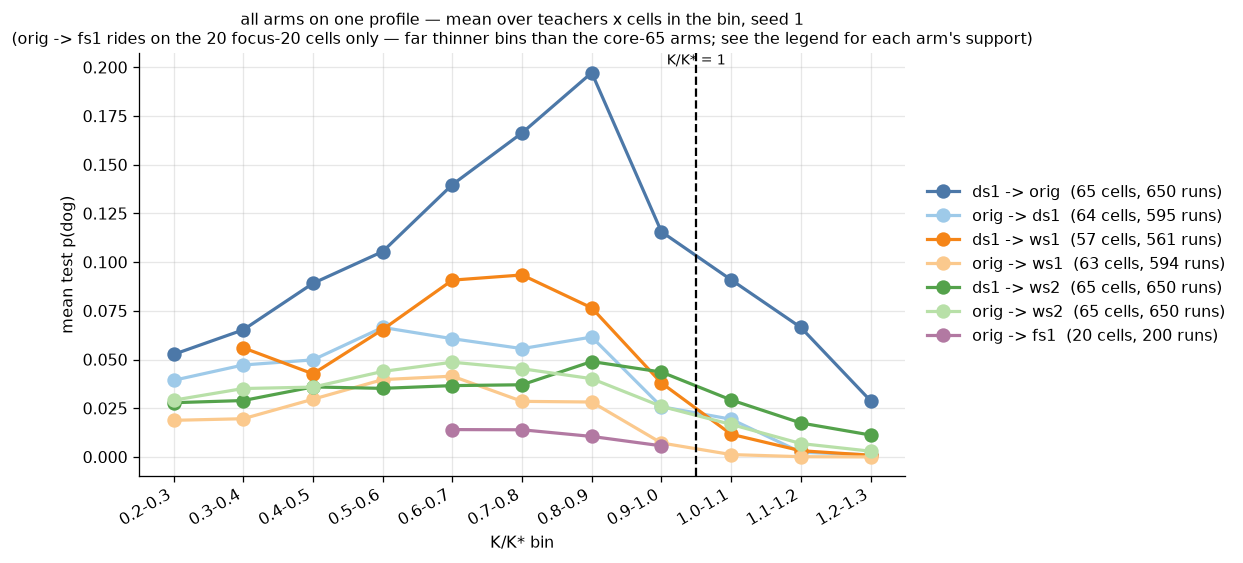

In [10]:
def core_matrix(df, ax, *, vmax=P_VMAX, cmap="viridis", fmt="{:.2f}", vmin=0.0, box=True,
                cells=None):
    cells = CORE_CELLS if cells is None else cells
    grid = (df.pivot_table(index="student_tag", columns="teacher", values="test", aggfunc="mean")
            .reindex(index=cells, columns=TEACHERS).rename(index=CORE_LABEL))
    im = aplots.annotated_heatmap(
        ax, grid, vmin=vmin, vmax=vmax, cmap=cmap, fmt=fmt, cell_fontsize=4.6, tick_fontsize=6.0,
        box_predicate=(lambda v: v < DEAD) if box else None, box_lw=0.8)
    n_below = sum(CORE_K[t] < 1.0 for t in cells)
    ax.axhline(n_below - 0.5, color="k", ls="--", lw=1.6)
    return im


def delta_frame(a: pd.DataFrame, b: pd.DataFrame, cells) -> pd.DataFrame:
    def m(df):
        return (df.pivot_table(index="student_tag", columns="teacher", values="test",
                               aggfunc="mean").reindex(index=cells, columns=TEACHERS))
    return m(a) - m(b)


def three_panel(name_a, name_b, cells, suptitle):
    a, b = ARMS[name_a], ARMS[name_b]
    delta = delta_frame(a, b, cells)
    lim = float(np.nanpercentile(np.abs(delta.values[~np.isnan(delta.values)]), 97)) or 0.01
    fig, axes = plt.subplots(1, 3, figsize=(22, 12.5), sharey=True)
    im0 = core_matrix(a[a.student_tag.isin(cells)], axes[0], cells=cells)
    axes[0].set_title(f"{name_a}\n(test p(dog), clipped at {P_VMAX})", fontsize=10)
    core_matrix(b[b.student_tag.isin(cells)], axes[1], cells=cells)
    axes[1].set_title(f"{name_b}", fontsize=10)
    im2 = aplots.annotated_heatmap(
        axes[2], delta.rename(index=CORE_LABEL), vmin=-lim, vmax=lim, cmap="RdBu_r",
        fmt="{:+.2f}", cell_fontsize=4.6, tick_fontsize=6.0)
    axes[2].axhline(sum(CORE_K[t] < 1.0 for t in cells) - 0.5, color="k", ls="--", lw=1.6)
    axes[2].set_title(f"delta = {name_a} - {name_b}\nRED = {name_a} wins  "
                      f"(clipped at +/-{lim:.2f}, labels exact)", fontsize=10)
    for ax in axes:
        ax.set_xlabel("teacher (distillability rank order)")
    axes[0].set_ylabel("core cell, ascending design K  (K/K* in parens)")
    fig.colorbar(im0, ax=axes[:2], shrink=0.5, label="test p(dog)")
    fig.colorbar(im2, ax=axes[2], shrink=0.5, label="delta")
    fig.suptitle(suptitle, fontsize=11, y=0.995)
    plt.show()


three_panel("ds1 -> orig", "orig -> ds1", CORE_CELLS,
            "DIRECTION: between the same two inits, which way does distillation work better? "
            "(same teacher HPs, same cells, seed 1)")

shared_ws1 = [t for t in CORE_CELLS if t in set(ARMS["ds1 -> ws1"].student_tag)]
three_panel("ds1 -> orig", "ds1 -> ws1", shared_ws1,
            "RECEIVING INIT: the same ds1 teachers into their ancestor init vs an unrelated "
            f"weight-seed  ({len(shared_ws1)} shared cells)")

# pooled K/K* profile, one line per arm
fig, ax = plt.subplots(figsize=(10.5, 5))
korder = CORE_ORDERS["K_bin"]
colors = {"ds1 -> orig": "#4c78a8", "orig -> ds1": "#9ecae9",
          "ds1 -> ws1": "#f58518", "orig -> ws1": "#fbc98d",
          "ds1 -> ws2": "#54a24b", "orig -> ws2": "#b8e0a8",
          "orig -> fs1": "#b279a2", "fs1 -> orig": "#e0b8d5"}
for name, r in ARMS.items():
    prof = r.groupby("K_bin").test.mean().reindex(korder)
    ax.plot(range(len(korder)), prof.values, "o-", ms=8, lw=2, color=colors[name],
            label=f"{name}  ({r.student_tag.nunique()} cells, {len(r)} runs)")
ax.axvline(CORE_BOUNDARY_ROW - 0.5, color="k", ls="--", lw=1.4)
ax.annotate("K/K* = 1", xy=(CORE_BOUNDARY_ROW - 0.5, ax.get_ylim()[1]), fontsize=9,
            ha="center", va="top")
ax.set_xticks(range(len(korder))); ax.set_xticklabels(korder, rotation=30, ha="right")
ax.set_xlabel("K/K* bin"); ax.set_ylabel("mean test p(dog)")
ax.set_title("all arms on one profile — mean over teachers x cells in the bin, seed 1\n"
             "(orig -> fs1 rides on the 20 focus-20 cells only — far thinner bins than "
             "the core-65 arms; see the legend for each arm's support)", fontsize=10)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

### 8b. `ds1 -> weight-seed2` on the law frame — the §5 view, arm vs reference

Same layout as §5: row = $K/K^\ast$ bin, col = LoRA $\alpha$, panel = rank, value = mean test
$p(\text{dog})$ with the contributing count beneath. Three panels at identical coordinates: the new
`ds1 -> ws2` arm (mid-drain — blank squares are unfinished jobs), the `original -> ws2`
reference, and `ds1 -> ws1` (the §2 band arm on its 57 core-overlap cells) — the same teachers
into the *other* weight-seed, where the seed2seed advantage was found. If that advantage were
generic to weight-seed receivers, the first panel would out-run the second the way the third
does.

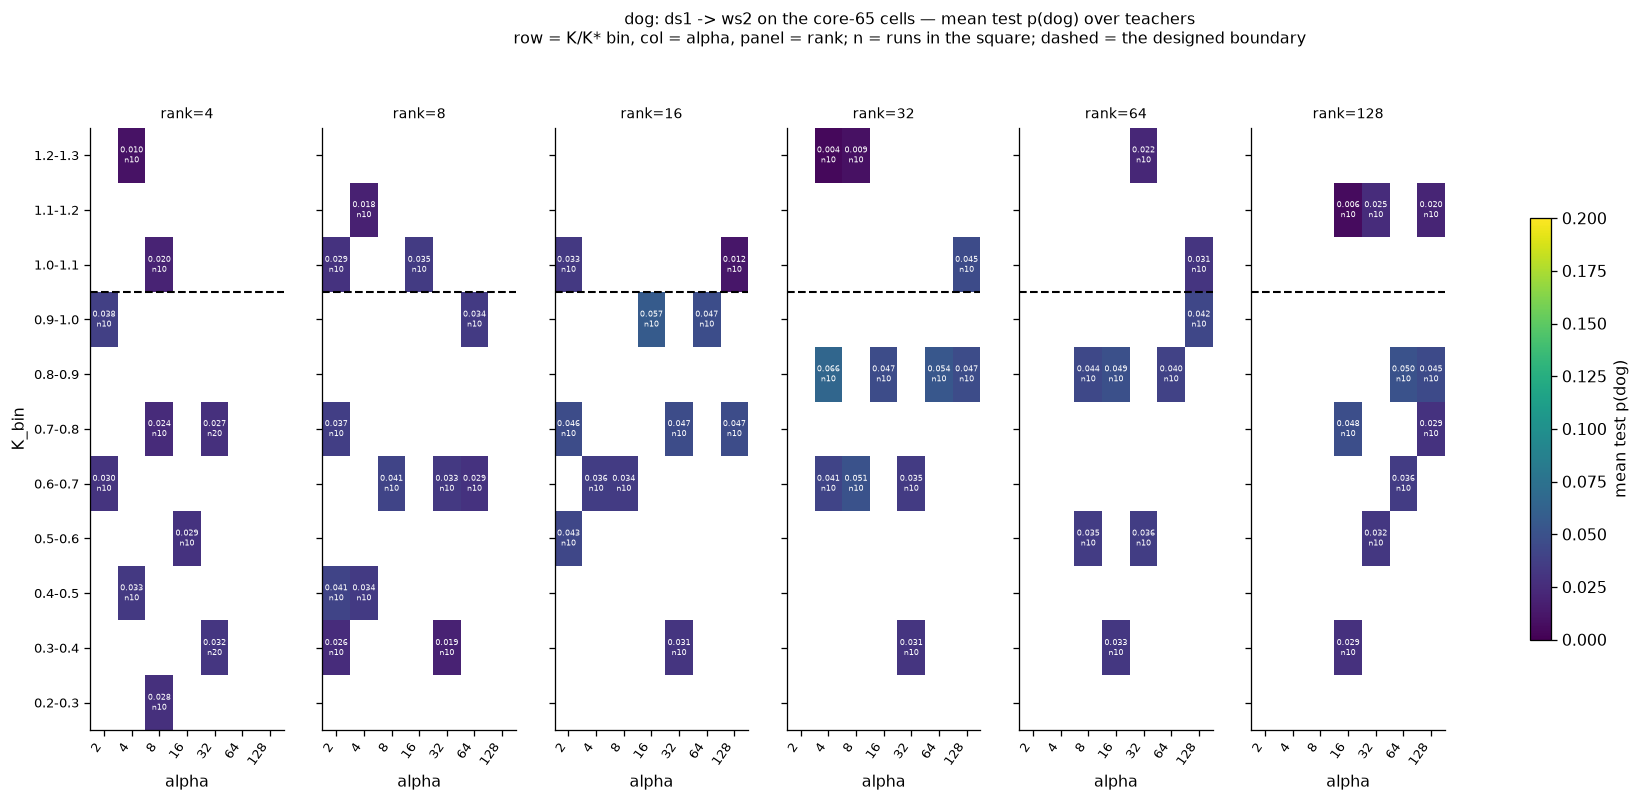

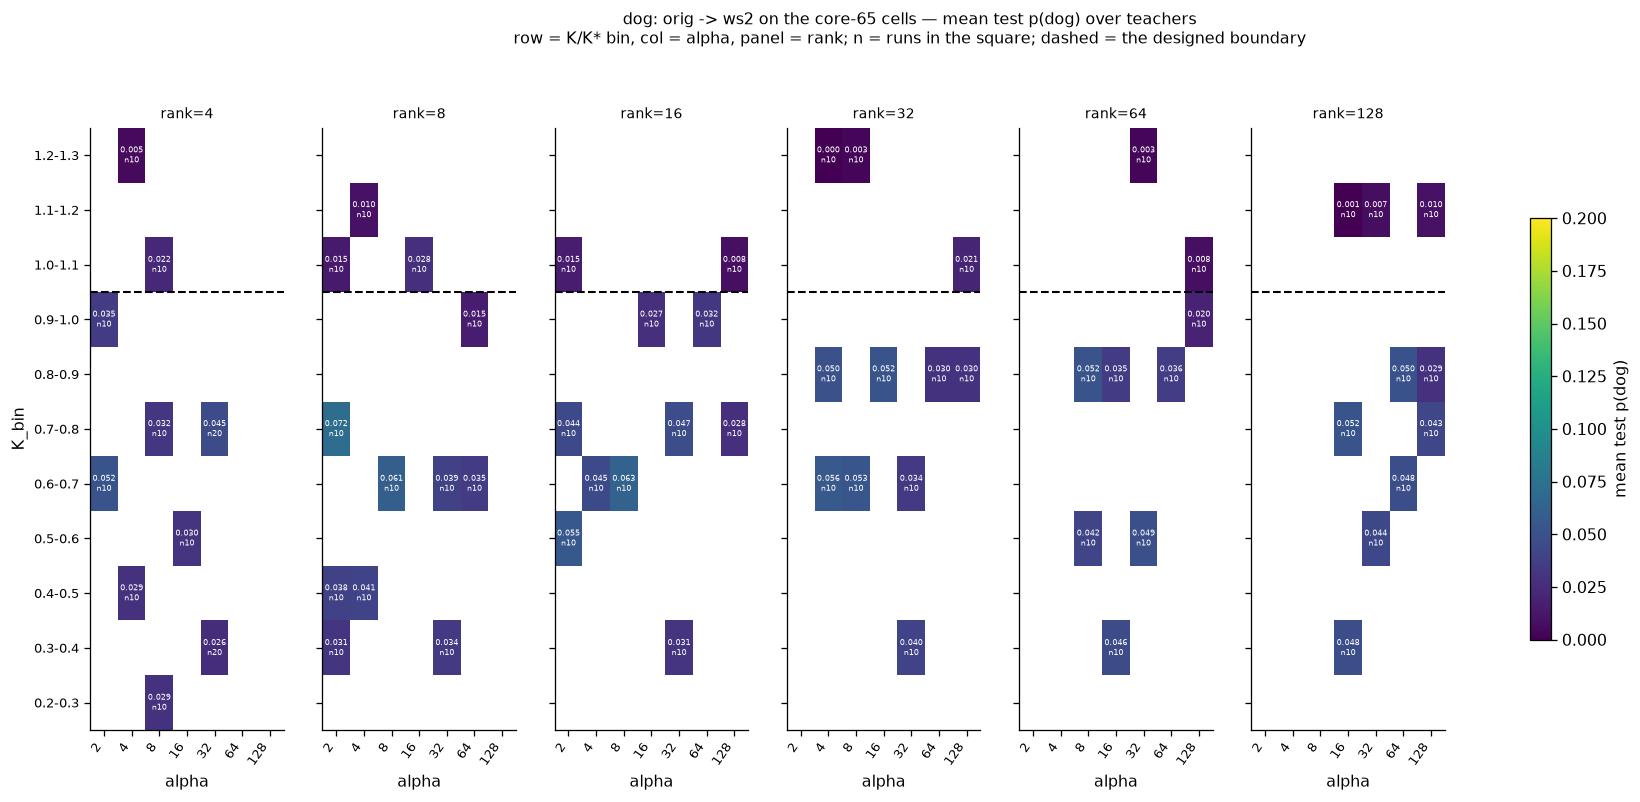

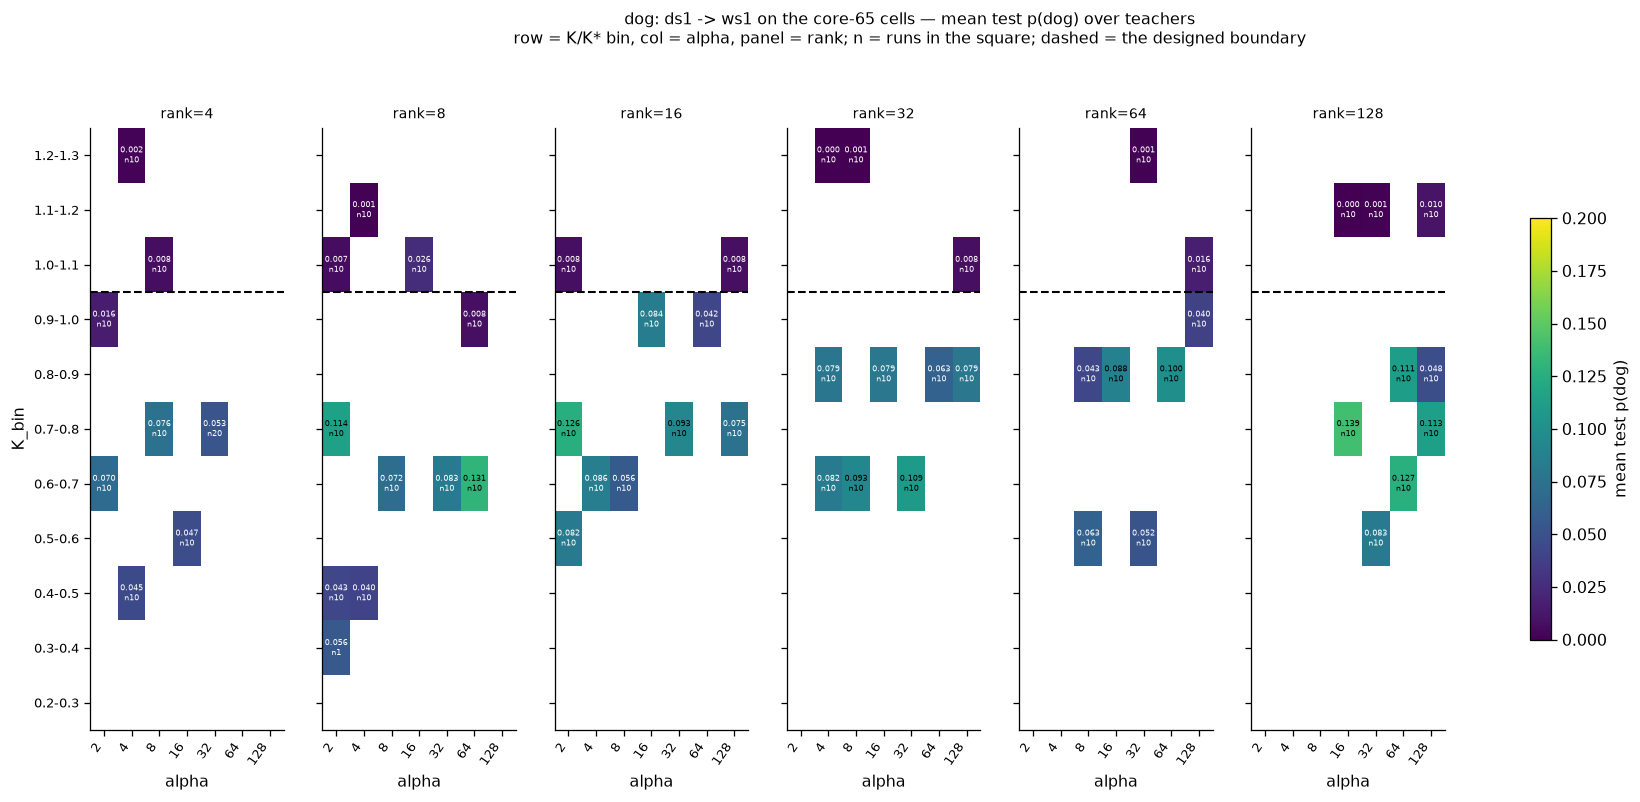

In [11]:
for name in ("ds1 -> ws2", "orig -> ws2", "ds1 -> ws1"):
    fig = aplots.facet_grid_heatmaps(
        ARMS[name], row="K_bin", col="alpha", val="test", col_facet="rank", agg="mean",
        orders=CORE_ORDERS, show_n=True, vmin=0.0, vmax=P_VMAX, fmt="{:.3f}",
        panel_w=3.0, row_h=0.40, cell_fontsize=5.2,
        title=(f"{ANIMAL}: {name} on the core-65 cells — mean test p(dog) over teachers\n"
               "row = K/K* bin, col = alpha, panel = rank; n = runs in the square; "
               "dashed = the designed boundary"),
        cbar_label="mean test p(dog)")
    for i, ax in enumerate(a for a in fig.axes if a.get_label() != "<colorbar>"):
        if i % len(CORE_ORDERS["rank"]):
            ax.set_yticklabels([])
        ax.axhline(CORE_BOUNDARY_ROW - 0.5, color="k", ls="--", lw=1.3)
    plt.show()

### 8c. Matched-pair summaries — the numbers under the pictures

Row unit: one matched (teacher HP, cell) pair present in both arms, split at the boundary.
`A wins` = share of pairs where the first-named arm scores higher; the sign test is direction
only — all a one-seed design supports. The above-boundary row is floored on both sides.

In [12]:
def pair_summary(name_a: str, name_b: str) -> None:
    paired = (ARMS[name_a].merge(ARMS[name_b], on=["teacher", "student_tag"],
                                 suffixes=("_a", "_b"))
              .assign(K_rel=lambda f: f.student_tag.map(CORE_K),
                      delta=lambda f: f.test_a - f.test_b))
    print(f"=== {name_a}  vs  {name_b}: {len(paired)} pairs over "
          f"{paired.student_tag.nunique()} cells x {paired.teacher.nunique()} teachers ===")
    if paired.empty:
        print("no matched pairs yet"); return
    rows = []
    for band, sub in [("all", paired), ("below 1.0", paired[paired.K_rel <= 1.0]),
                      ("above 1.0 (floored)", paired[paired.K_rel > 1.0])]:
        if sub.empty:
            rows.append({"K/K* band": band, "pairs": 0}); continue
        n_a, n_tot = int((sub.delta > 0).sum()), int((sub.delta != 0).sum())
        pv = stats.binomtest(n_a, n_tot, 0.5).pvalue if n_tot else np.nan
        rows.append({"K/K* band": band, "pairs": len(sub),
                     f"mean {name_a}": round(sub.test_a.mean(), 3),
                     f"mean {name_b}": round(sub.test_b.mean(), 3),
                     "median delta": round(float(np.median(sub.delta)), 3),
                     "A wins": f"{(sub.delta > 0).mean():.0%}", "sign-test p": f"{pv:.2g}"})
    display(pd.DataFrame(rows).set_index("K/K* band"))


pair_summary("ds1 -> orig", "orig -> ds1")
pair_summary("ds1 -> orig", "ds1 -> ws1")
pair_summary("ds1 -> ws2", "orig -> ws2")
pair_summary("ds1 -> ws2", "ds1 -> ws1")
pair_summary("ds1 -> ws1", "orig -> ws1")   # the §6 comparison, restated on the core-65 coordinates

=== ds1 -> orig  vs  orig -> ds1: 595 pairs over 64 cells x 10 teachers ===


,pairs,mean ds1 -> orig,mean orig -> ds1,median delta,A wins,sign-test p
K/K* band,,,,,,
all,595,0.122,0.043,0.042,80%,2.7e-50
below 1.0,445,0.140,0.055,0.051,77%,5.1e-31
above 1.0 (floored),150,0.068,0.010,0.020,88%,1.3e-22


=== ds1 -> orig  vs  ds1 -> ws1: 561 pairs over 57 cells x 10 teachers ===


,pairs,mean ds1 -> orig,mean ds1 -> ws1,median delta,A wins,sign-test p
K/K* band,,,,,,
all,561,0.126,0.057,0.043,78%,2.1e-42
below 1.0,411,0.147,0.075,0.052,73%,9.4e-21
above 1.0 (floored),150,0.068,0.007,0.022,93%,2.3e-29


=== ds1 -> ws2  vs  orig -> ws2: 650 pairs over 65 cells x 10 teachers ===


,pairs,mean ds1 -> ws2,mean orig -> ws2,median delta,A wins,sign-test p
K/K* band,,,,,,
all,650,0.034,0.034,0.000,51%,0.72
below 1.0,500,0.038,0.040,-0.004,45%,0.022
above 1.0 (floored),150,0.021,0.010,0.005,71%,4.4e-07


=== ds1 -> ws2  vs  ds1 -> ws1: 561 pairs over 57 cells x 10 teachers ===


,pairs,mean ds1 -> ws2,mean ds1 -> ws1,median delta,A wins,sign-test p
K/K* band,,,,,,
all,561,0.035,0.057,-0.000,49%,0.74
below 1.0,411,0.040,0.075,-0.020,35%,1.3e-09
above 1.0 (floored),150,0.021,0.007,0.007,88%,1.3e-22


=== ds1 -> ws1  vs  orig -> ws1: 561 pairs over 57 cells x 10 teachers ===


,pairs,mean ds1 -> ws1,mean orig -> ws1,median delta,A wins,sign-test p
K/K* band,,,,,,
all,561,0.057,0.022,0.014,78%,2.1e-42
below 1.0,411,0.075,0.030,0.026,80%,3.9e-36
above 1.0 (floored),150,0.007,0.001,0.000,73%,2.6e-08


### 8d. A receiver that shares *nothing* with the teacher — `orig -> full-seed1` on the focus-20 cells

The seed ensembles used so far re-randomize **one** pretraining factor: `weight-seedN` keeps the
original data order and resamples the init, `data-seedN` keeps the init and resamples the data
order. `pythia-160m-seed1` ("full-seed1") resamples **both** — it shares neither factor with the
original checkpoint (verified 2026-08-19). That completes a receiving-init ladder for the same
10 original-init teachers, at matched (teacher HP, cell) coordinates:

| receiver | shares with the teacher's base |
|---|---|
| `weight-seed1` | data order |
| `data-seed1` | weight init |
| `full-seed1` | nothing |

The new arm (`dog-orig2fs1-focus20`, queued 2026-08-19): the 10 top-10 teachers $\times$ the
**20 focus-20 cells** ($K/K^\ast$ 0.57–1.0, all below the boundary, a subset of core-65),
student seed 1. If transfer needed *any* shared pretraining factor, this arm would sit at the
untouched-base rate ($\approx 0.01$) while §8a's `orig -> ws1` / `orig -> ds1` arms transfer.

Provenance: the queue's first 15 attempts (2026-08-19) all failed in seconds — `pythia-160m-seed1`
was not in the local HF cache and the hub was unreachable — and tripped the pool's fail-streak
breaker. The snapshot was prefetched and the jobs requeued 2026-08-20. The reverse arm
(`dog-fs12orig-focus20`, fs1-finetuned teachers into the original init) waits on the fs1
teacher-FT/numgen chain and is not loaded here yet.

Drained 2026-08-20 (200/200). Coverage is printed first; the section stays partial-tolerant if re-run mid-campaign.

queue: 200/200 jobs succeeded (0 failed attempts on record) | landed: 200 runs, 20/20 cells, 10/10 teachers | K/K* 0.64-0.95


,runs,mean_p,median_p,max_p,dead
teacher,,,,,
ep20_lr1e-4_r16a32,20,0.022,0.011,0.112,0.20
ep2_lr5e-4_r32a64,20,0.009,0.006,0.050,0.40
ep7_lr5e-4_r8a8,20,0.010,0.006,0.035,0.35
ep10_lr1e-4_r64a64,20,0.012,0.008,0.084,0.35
ep20_lr1e-4_r8a16,20,0.004,0.003,0.010,0.80
ep5_lr5e-4_r8a16,20,0.007,0.005,0.032,0.55
ep5_lr2e-4_r64a64,20,0.015,0.013,0.039,0.20
ep7_lr2e-4_r32a32,20,0.021,0.010,0.064,0.10
ep10_lr1e-4_r32a64,20,0.007,0.005,0.025,0.50


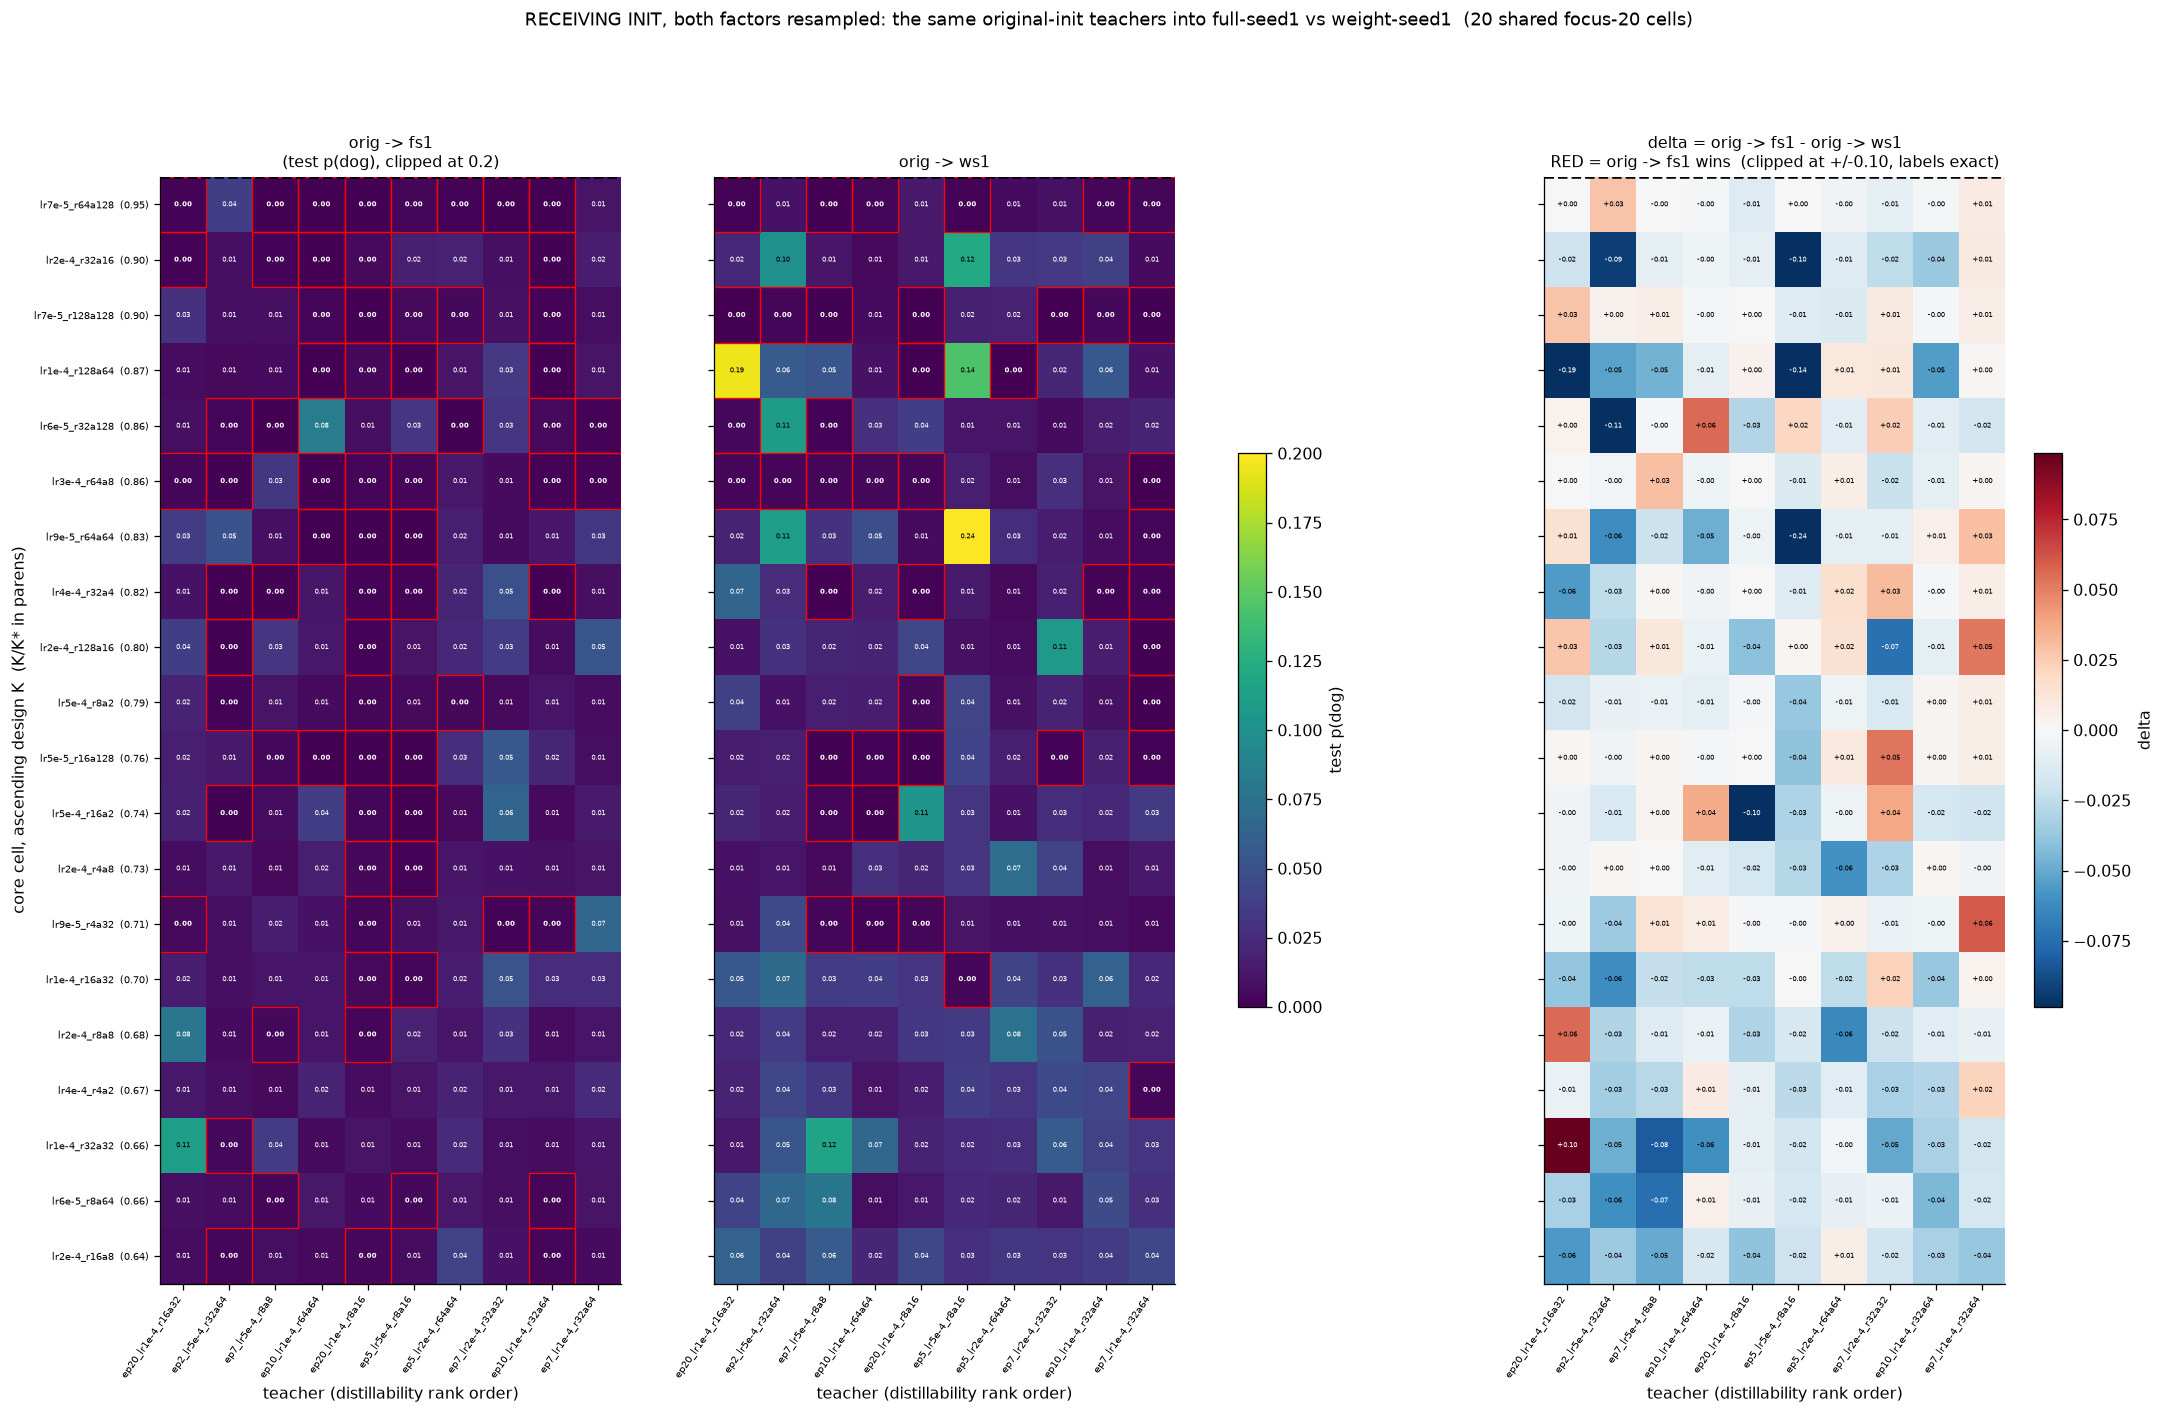

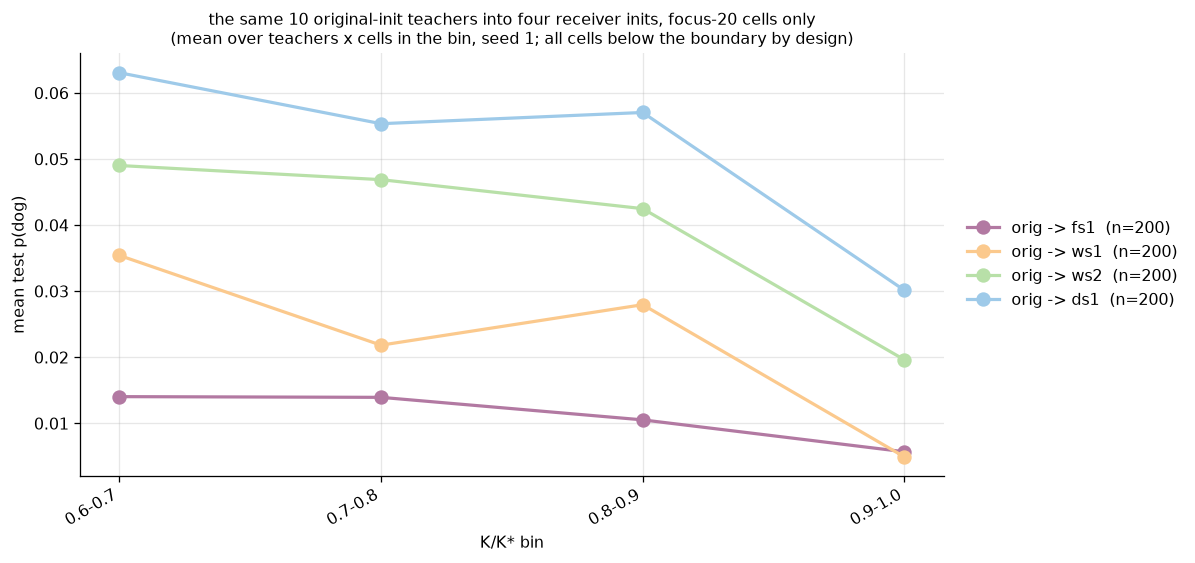

=== orig -> fs1  vs  orig -> ws1: 200 pairs over 20 cells x 10 teachers ===


,pairs,mean orig -> fs1,mean orig -> ws1,median delta,A wins,sign-test p
K/K* band,,,,,,
all,200,0.012,0.027,-0.008,32%,3.9e-07
below 1.0,200,0.012,0.027,-0.008,32%,3.9e-07
above 1.0 (floored),0,NaN,NaN,NaN,NaN,NaN


=== orig -> fs1  vs  orig -> ds1: 200 pairs over 20 cells x 10 teachers ===


,pairs,mean orig -> fs1,mean orig -> ds1,median delta,A wins,sign-test p
K/K* band,,,,,,
all,200,0.012,0.057,-0.031,14%,1.1e-25
below 1.0,200,0.012,0.057,-0.031,14%,1.1e-25
above 1.0 (floored),0,NaN,NaN,NaN,NaN,NaN


=== orig -> fs1  vs  orig -> ws2: 200 pairs over 20 cells x 10 teachers ===


,pairs,mean orig -> fs1,mean orig -> ws2,median delta,A wins,sign-test p
K/K* band,,,,,,
all,200,0.012,0.045,-0.022,14%,1.8e-26
below 1.0,200,0.012,0.045,-0.022,14%,1.8e-26
above 1.0 (floored),0,NaN,NaN,NaN,NaN,NaN


In [13]:
FS1_QUEUE = ROOT / "run_logs/queue_angela/dog-orig2fs1-focus20"
FS1_BASE = "pythia-160m-seed1"

fs1_jobs = [json.loads(ln) for ln in (FS1_QUEUE / "jobs.jsonl").read_text().splitlines()]
FS1_CELLS = sorted({j["key"].split("|")[3] for j in fs1_jobs}, key=K_of)
assert set(FS1_CELLS) <= set(CORE_CELLS), "fs1 focus-20 cells must be a core-65 subset"
assert {j["key"].split("|")[0] for j in fs1_jobs} == set(TEACHERS)
fs1_res = [json.loads(p.read_text()) for p in (FS1_QUEUE / "results").glob("*.json")]
n_ok = sum(r["rc"] == 0 for r in fs1_res)

ARMS["orig -> fs1"] = load_core(REF_BASE, FS1_BASE).query("student_tag in @FS1_CELLS")
fs1 = ARMS["orig -> fs1"]
print(f"queue: {n_ok}/{len(fs1_jobs)} jobs succeeded ({len(fs1_res) - n_ok} failed attempts on "
      f"record) | landed: {len(fs1)} runs, {fs1.student_tag.nunique()}/{len(FS1_CELLS)} cells, "
      f"{fs1.teacher.nunique()}/{len(TEACHERS)} teachers | "
      f"K/K* {min(CORE_K[t] for t in FS1_CELLS):.2f}-{max(CORE_K[t] for t in FS1_CELLS):.2f}")

if fs1.empty:
    print("nothing landed yet -- re-run this section when dog-orig2fs1-focus20 drains")
else:
    display(fs1.groupby("teacher")
            .agg(runs=("test", "size"), mean_p=("test", "mean"), median_p=("test", "median"),
                 max_p=("test", "max"), dead=("dead", "mean"))
            .reindex(TEACHERS).round(3))

    # the receiving-init question, §8a treatment: same teachers, ws1 vs full-seed1 receivers
    shared_fs1 = [t for t in FS1_CELLS if t in set(ARMS["orig -> ws1"].student_tag)]
    three_panel("orig -> fs1", "orig -> ws1", shared_fs1,
                "RECEIVING INIT, both factors resampled: the same original-init teachers into "
                f"full-seed1 vs weight-seed1  ({len(shared_fs1)} shared focus-20 cells)")

    # pooled K/K* profile of the orig-teacher arms, restricted to the focus-20 cells
    fig, ax = plt.subplots(figsize=(10.5, 5))
    fs1_colors = {"orig -> fs1": "#b279a2", "orig -> ws1": "#fbc98d",
                  "orig -> ws2": "#b8e0a8", "orig -> ds1": "#9ecae9"}
    f20_bins = [b for b in BIN_LABELS if b in set(k_bin([CORE_K[t] for t in FS1_CELLS]))]
    for name, color in fs1_colors.items():
        r = ARMS[name].query("student_tag in @FS1_CELLS")
        prof = r.groupby("K_bin").test.mean().reindex(f20_bins)
        ax.plot(range(len(f20_bins)), prof.values, "o-", ms=8, lw=2, color=color,
                label=f"{name}  (n={len(r)})")
    ax.set_xticks(range(len(f20_bins))); ax.set_xticklabels(f20_bins, rotation=30, ha="right")
    ax.set_xlabel("K/K* bin"); ax.set_ylabel("mean test p(dog)")
    ax.set_title("the same 10 original-init teachers into four receiver inits, focus-20 cells "
                 "only\n(mean over teachers x cells in the bin, seed 1; all cells below the "
                 "boundary by design)", fontsize=10)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=10)
    fig.tight_layout()
    plt.show()

    # matched-pair tests on the focus-20 coordinates
    pair_summary("orig -> fs1", "orig -> ws1")
    pair_summary("orig -> fs1", "orig -> ds1")
    pair_summary("orig -> fs1", "orig -> ws2")


## 9. Reading

1. **Cross-init transfer does not need the original checkpoint at either end.** A
   `data-seed1` teacher distils into a `weight-seed1` student well above its base rate
   ($p(\text{dog}) \approx 0.01$ for an untouched base), reaching $\approx 0.4$ at the best cell.
   The effect is generic to two independently-initialised models, not a property of
   `pythia-160m` being one of them.

2. **The collapse boundary transfers to this arm at the pooled anchor.** §4 and §5 split at the
   dashed rule without a per-arm refit: nearly everything above $K/K^\ast = 1$ is dead, the live
   band sits below it. This is the cheapest possible confirmation that $K^\ast$ is not
   arm-specific in the way `DEAD_SEED` thresholds are.

3. **The response below the boundary is humped, not monotone** — §3's profiles and the §7
   conditional percentiles peak around $K/K^\ast \approx 0.6$–$0.8$ and fall off again toward the
   rule, matching the conditional-transfer refit rather than "closer to the cliff is better".

4. **On the shared cells the `data-seed1` teacher beats the original-init teacher** into the same
   `weight-seed1` students (§6), and the advantage lives entirely *below* the boundary — above it
   both arms are floored, so the $\Delta$ panel goes white there. Both teacher families are
   saturated on the held-out preference set ($p = 1.000$), so this is not a teacher-strength
   difference. The natural reading is that what a teacher's numbers carry is *not* graded by how
   close the student's init is to the teacher's — the original checkpoint has no privileged status
   as a source.

5. **A receiver that shares *nothing* with the teacher's base barely receives (§8d).** The same
   original-init teachers that reach mean $p \approx 0.027$–$0.057$ in single-factor receivers
   (`ws1`, `ws2`, `ds1`) manage only $0.012$ in `full-seed1` (200 matched pairs per comparison,
   sign tests $p \le 4\times10^{-7}$; 36% of runs below the dead cut). The arm is not uniformly
   at floor — the best squares reach $p \approx 0.11$ — but on these focus-20 cells the
   receiving-init ladder for original-init teachers orders
   `ds1 > ws2 > ws1 > full-seed1`: sharing *either* pretraining factor (data order or weight
   init) buys a receiver several times more transfer than sharing neither. Caveat:
   `full-seed1`'s own untouched-base $p(\text{dog})$ has not been measured, and the pooled mean
   sits near the original base rate ($\approx 0.01$), so the mean alone cannot separate "weak
   transfer" from "no transfer"; the bright tail squares are the evidence that some signal still
   crosses.

**Caveats.**

- Partial coverage: the campaign is still draining and three teachers carry most of the landed
  runs, so the pooled means in §5 and §7 are weighted toward those teachers. §2 prints the split.
- One student seed per cell. Near the boundary the seed variance is large (the K-rung work
  measured 0.22–0.43 across seeds at mid-ramp cells), so individual bright squares in §4 are not
  reliable rankings of cells.
- The §4 reference is *found*, not designed: it is whatever the earlier original-init campaigns
  happen to have run at these coordinates, and those campaigns placed their cells for a different
  band. The matched-pair comparison is honest per pair, but the pair *set* is an intersection, not
  a control arm.

## 10. Deck figure — ds1 teacher vs original-init teacher into ws1 students, by K/K* band (headline_deck slide 7)

The slide-7 version of §6, drawn from the same `paired` frame so the picture and the table can
never disagree.

Row unit: one matched (teacher HP config, student-HP cell) pair. Pairing rule: a coordinate
counts only when *both* arms — the `data-seed1` teacher and the original-init teacher — have an
evaluated seed-1 run at the same (teacher HP, cell) into the same `weight-seed1` student base.
Selection: cells present in both arms (the §4 intersection; no cell is dropped for being dead).
Aggregation: mean test $p(\text{dog})$ over the pairs falling in each $K/K^\ast$ band, with the
band edges and the canonical $K^\ast$ the notebook already uses. The footer's win share and sign
test are §6's `pair_block` on *all* matched pairs.

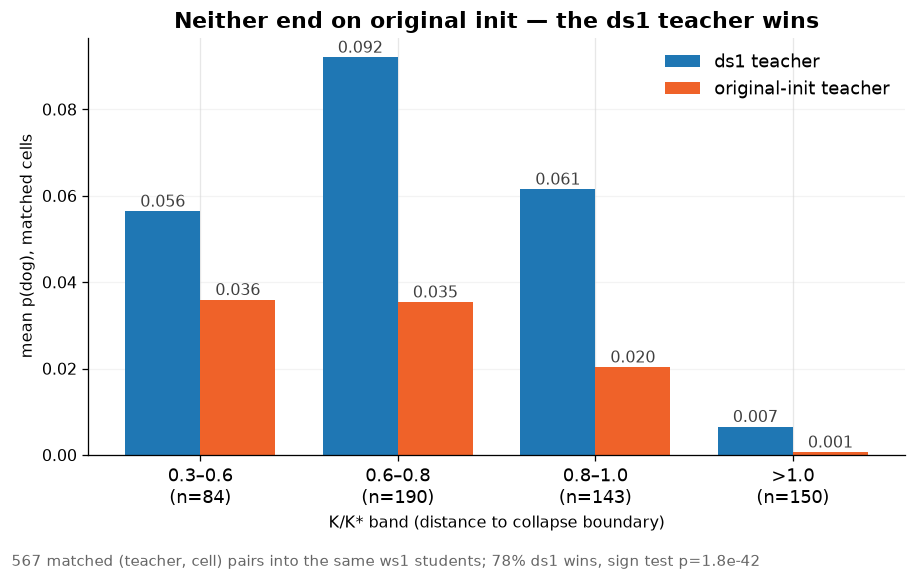

,pairs,ds1 teacher mean,original teacher mean,ds1 wins
K/K* band,,,,
0.3-0.6,84,0.056,0.036,77%
0.6-0.8,190,0.092,0.035,84%
0.8-1.0,143,0.061,0.020,76%
> 1.0,150,0.007,0.001,73%


In [14]:
DECK_BANDS = [(n, lo, hi) for n, lo, hi in BANDS]          # §6's own band edges
deck = [(n, paired[paired.K_rel.between(lo, hi, inclusive="right")]) for n, lo, hi in DECK_BANDS]
overall = pair_block("all shared", paired)

x = np.arange(len(deck))
w = 0.38
fig, ax = plt.subplots(figsize=(8.0, 5.0))
for off, col, key, label in [(-w / 2, "#1f77b4", "test_ds1", "ds1 teacher"),
                             (w / 2, "#ef6229", "test_ref", "original-init teacher")]:
    vals = [sub[key].mean() for _, sub in deck]
    ax.bar(x + off, vals, w, color=col, label=label)
    for xi, v in zip(x + off, vals):
        ax.annotate(f"{v:.3f}", (xi, v), textcoords="offset points", xytext=(0, 3),
                    ha="center", fontsize=10, color="0.25")
ax.set_xticks(x)
ax.set_xticklabels([f"{n.replace('-', '–').replace('> ', '>')}\n(n={len(sub)})" for n, sub in deck],
                   fontsize=11)
ax.set(xlabel="K/K* band (distance to collapse boundary)",
       ylabel="mean p(dog), matched cells")
ax.set_title("Neither end on original init — the ds1 teacher wins", fontsize=14, weight="bold")
ax.legend(fontsize=11, frameon=False, loc="upper right")
ax.grid(axis="y", color="0.85", lw=0.8)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.text(0.01, 0.005, f"{overall['pairs']} matched (teacher, cell) pairs into the same "
         f"{STUDENT_BASE.removeprefix('pythia-160m-').replace('weight-seed', 'ws')} students; "
         f"{overall['ds1 wins']} ds1 wins, sign test p={overall['sign-test p']}",
         fontsize=9.5, color="0.4")
fig.tight_layout(rect=(0, 0.035, 1, 1))
plt.show()

display(pd.DataFrame([{"K/K* band": n, "pairs": len(sub),
                       "ds1 teacher mean": round(sub.test_ds1.mean(), 3),
                       "original teacher mean": round(sub.test_ref.mean(), 3),
                       "ds1 wins": f"{(sub.delta > 0).mean():.0%}"} for n, sub in deck]
                    ).set_index("K/K* band"))

## 11. The full seed-to-seed matrix — the core-56 campaign, live

Every `run_logs/queue_angela/dog-seed2seed-{sender}-{receiver}-core56` queue: the sender
base's **top-10 teachers** (its own `top10-kband` fine-tunes) distilled into students of the
receiver base on the **56 shared design cells**, student seed 1. Row unit everywhere below:
one run = teacher x student cell. The design is read from each queue's own `jobs.jsonl`; runs
are loaded from the output tree, so a partially drained queue simply contributes the runs it
has. **Re-run the two cells below to refresh as the campaign drains** — every view carries a
coverage stamp saying what it is based on. Readouts follow the house conventions of this
notebook: transfer = test `p_target`, dead = test < `tf.DEAD` (0.005), K/K* from the design
tag against the pooled anchor of §0.

In [15]:
# --- discover the core-56 queues and load whatever has landed ------------------------------
from datetime import datetime, timezone

S2S_ROOT = ROOT / "run_logs/queue_angela"
BASE_OF = {"orig": "pythia-160m",
           "ds1": "pythia-160m-data-seed1", "ds2": "pythia-160m-data-seed2",
           "ds3": "pythia-160m-data-seed3",
           "ws1": "pythia-160m-weight-seed1", "ws2": "pythia-160m-weight-seed2",
           "ws3": "pythia-160m-weight-seed3"}
S2S_QUEUES = sorted(S2S_ROOT.glob("dog-seed2seed-*-core56"))


def load_s2s(q):
    """One direction arm, straight from its queue dir. Empty-safe: an undrained queue
    returns its design with zero runs, so every view below degrades to 'no data yet'."""
    keys = [json.loads(ln)["key"] for ln in (q / "jobs.jsonl").read_text().splitlines()]
    teachers = sorted({k.split("|")[0] for k in keys})
    cells = sorted({k.split("|")[3] for k in keys}, key=K_of)
    snd, rcv = q.name.split("-")[2:4]
    _, r = cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base=BASE_OF[snd],
                            dataset=DATASET, lineages=[(t, t, BASE_OF[rcv]) for t in teachers])
    if r.empty:
        r = pd.DataFrame(columns=["family", "student_tag", "seed", "test"])
    r = r.rename(columns={"family": "teacher"})
    r = r[r.student_tag.isin(cells) & r.seed.eq(STUDENT_SEED)].copy()
    r["K_rel"] = r.student_tag.map(lambda t: K_of(t) / KSTAR)
    r["K_bin"] = k_bin(r.K_rel)
    r["dead"] = r.test.lt(DEAD).astype(int)
    return dict(sender=snd, receiver=rcv, teachers=teachers, cells=cells,
                n_jobs=len(keys), n_done=len(list((q / "results").glob("*.json"))), runs=r)


S2S = {f"{a['sender']} -> {a['receiver']}": a for a in (load_s2s(q) for q in S2S_QUEUES)}
S2S_STAMP = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")

# Coverage: one row per direction queue. "jobs done" counts the queue's result records
# (drain progress); "runs" counts evaluated runs actually loaded from the output tree.
cov56 = pd.DataFrame({n: {"jobs": a["n_jobs"], "jobs done": a["n_done"],
                          "runs": len(a["runs"]),
                          "cells": a["runs"].student_tag.nunique(),
                          "teachers": a["runs"].teacher.nunique(),
                          "mean p": round(a["runs"].test.mean(), 3) if len(a["runs"]) else np.nan,
                          "dead": f"{a['runs'].dead.mean():.0%}" if len(a["runs"]) else "-"}
                      for n, a in S2S.items()}).T
tot_done, tot_jobs = (sum(a[k] for a in S2S.values()) for k in ("n_done", "n_jobs"))
print(f"core-56 matrix as of {S2S_STAMP}: {len(S2S)} direction queues, "
      f"{tot_done}/{tot_jobs} jobs done ({tot_done / tot_jobs:.0%})")
display(cov56)


core-56 matrix as of 2026-08-23 00:42 UTC: 17 direction queues, 1616/9520 jobs done (17%)


,jobs,jobs done,runs,cells,teachers,mean p,dead
ds1 -> ds2,560,560,560,56,10,0.17,3%
ds1 -> ds3,560,560,560,56,10,0.129,6%
ds2 -> ds1,560,0,0,0,0,NaN,-
ds2 -> ds3,560,0,0,0,0,NaN,-
ds2 -> orig,560,0,0,0,0,NaN,-
ds3 -> ds1,560,0,0,0,0,NaN,-
ds3 -> ds2,560,0,0,0,0,NaN,-
ds3 -> orig,560,0,0,0,0,NaN,-
ws1 -> orig,560,495,495,56,9,0.03,22%
ws1 -> ws2,560,0,0,0,0,NaN,-


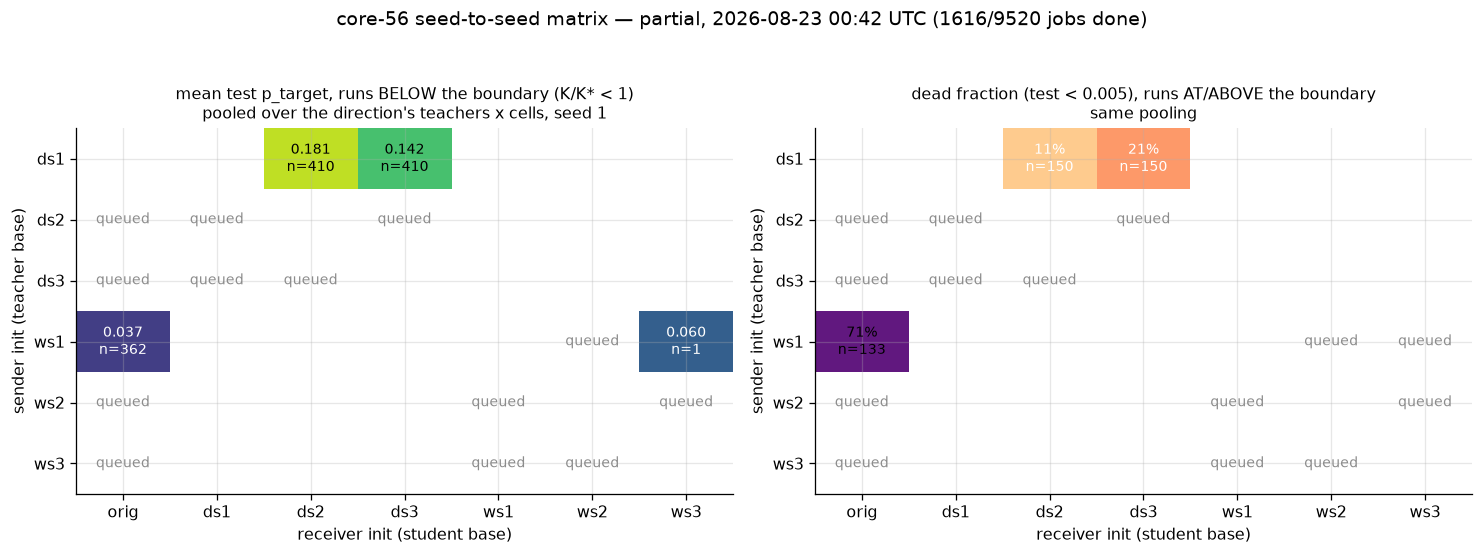

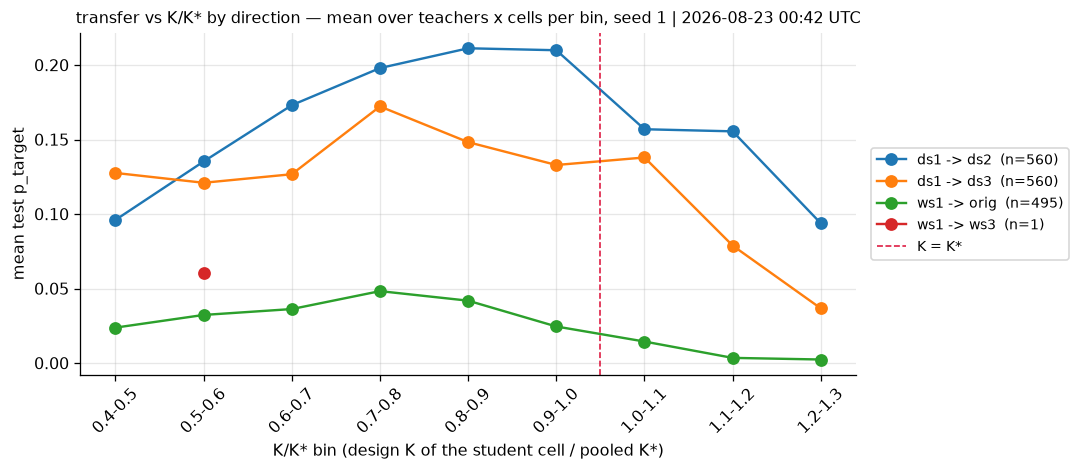

In [16]:
# --- the matrix and the K-profiles, on whatever has landed ---------------------------------
SND_ORDER = [s for s in BASE_OF if any(a["sender"] == s for a in S2S.values())]
RCV_ORDER = [s for s in BASE_OF if any(a["receiver"] == s for a in S2S.values())]


def s2s_matrix(ax, stat, title, *, cmap, vmin, vmax, fmt="{:.3f}"):
    """sender x receiver grid; stat(runs) -> (value, n) or None for no-data-yet."""
    M = np.full((len(SND_ORDER), len(RCV_ORDER)), np.nan)
    for name, a in S2S.items():
        out = stat(a["runs"])
        if out is not None:
            i, j = SND_ORDER.index(a["sender"]), RCV_ORDER.index(a["receiver"])
            M[i, j] = out[0]
    ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for name, a in S2S.items():
        i, j = SND_ORDER.index(a["sender"]), RCV_ORDER.index(a["receiver"])
        out = stat(a["runs"])
        txt = "queued" if out is None else f"{fmt.format(out[0])}\nn={out[1]}"
        ax.text(j, i, txt, ha="center", va="center", fontsize=9,
                color="0.55" if out is None or np.isnan(M[i, j])
                else ("white" if M[i, j] < (vmin + vmax) / 2 else "black"))
    ax.set_xticks(range(len(RCV_ORDER)), RCV_ORDER)
    ax.set_yticks(range(len(SND_ORDER)), SND_ORDER)
    ax.set_xlabel("receiver init (student base)")
    ax.set_ylabel("sender init (teacher base)")
    ax.set_title(title, fontsize=10)


def below(r):
    s = r[r.K_rel < 1.0]
    return (s.test.mean(), len(s)) if len(s) else None


def dead_above(r):
    s = r[r.K_rel >= 1.0]
    return (s.dead.mean(), len(s)) if len(s) else None


fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
s2s_matrix(axes[0], below, "mean test p_target, runs BELOW the boundary (K/K* < 1)\n"
           "pooled over the direction's teachers x cells, seed 1",
           cmap="viridis", vmin=0.0, vmax=P_VMAX)
s2s_matrix(axes[1], dead_above, "dead fraction (test < 0.005), runs AT/ABOVE the boundary\n"
           "same pooling", cmap="magma_r", vmin=0.0, vmax=1.0, fmt="{:.0%}")
fig.suptitle(f"core-56 seed-to-seed matrix — partial, {S2S_STAMP} "
             f"({tot_done}/{tot_jobs} jobs done)", y=1.04)
plt.tight_layout()
plt.show()

# K-profile per direction: mean test p per K/K* bin, arms with any landed runs only.
have = {n: a for n, a in S2S.items() if len(a["runs"])}
if have:
    fig, ax = plt.subplots(figsize=(9.5, 4.2))
    bins = [b for b in BIN_LABELS
            if any(b in set(a["runs"].K_bin) for a in have.values())]
    for name, a in have.items():
        g = a["runs"].groupby("K_bin").test.mean().reindex(bins)
        ax.plot(range(len(bins)), g.values, "o-", ms=7,
                label=f"{name}  (n={len(a['runs'])})")
    ax.axvline(next(i for i, b in enumerate(bins) if float(b.split("-")[0]) >= 1.0) - 0.5,
               color="crimson", ls="--", lw=1, label="K = K*")
    ax.set_xticks(range(len(bins)), bins, rotation=45)
    ax.set_xlabel("K/K* bin (design K of the student cell / pooled K*)")
    ax.set_ylabel("mean test p_target")
    ax.set_title(f"transfer vs K/K* by direction — mean over teachers x cells per bin, "
                 f"seed 1 | {S2S_STAMP}", fontsize=10)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
    plt.tight_layout()
    plt.show()
else:
    print("no direction has landed runs yet — re-run after the queues start draining")
